# TP1 · Task 5: Final model selection and evaluation
## Classification of abnormal electric-vehicle charging sessions

**Course:** Mineração de Dados (MINDD), 2026/2027, 1st semester, ISEP / DEI

**Dataset:** educational version of the *China EV Charging Dataset* (Zhang et al., 2025). It has 441,077 charging sessions,
92 charging posts, 13 stations and 3 districts, from 2020 to 2021.

Task 5 closes the project. We justify the choice of the final model with development results only, refit it on all development data
with every decision fixed, compare it with the baseline on the final test period, and then study where and why it works or fails: over
time, across districts, stations and charging posts, and in its false positives and false negatives. We interpret the model, explain what
the selected threshold means in practice, and judge whether the model would be useful to the operator.

Task 4 already scored the test period once, on 2026-10-27, because its brief asks for it.
This notebook starts from the same frozen file (`prepared/task4_frozen.json`), refits the same model and reproduces the Task 4 test
numbers in Section 4 as a check. No model, feature, hyperparameter or cut-off is changed. Everything that uses the test labels after that
point (subgroups, error analysis, importance on the test period) is descriptive and cannot change a decision.

### How to read this notebook

| # | Section | Requirement of the Task 5 brief |
|---|---------|---------------------------------|
| 1 | Setup and inputs | — |
| 2 | Selecting the final model and the baseline | selection with training and validation results only: performance, temporal stability, computational cost, interpretability, operational implications; an appropriate baseline |
| 3 | Refit on all development data and fix the decisions | refit on all development data; preprocessing, features, hyperparameters and threshold fixed before the test |
| 4 | Scoring the test period | one evaluation on the final test period |
| 5 | Final model against the baseline | PR-AUC; precision, recall, F1; balanced accuracy, MCC; alert rate; correct, false and missed alerts per 1,000 sessions |
| 6 | Performance across time | relevant time periods |
| 7 | Performance across operational groups | districts, charging posts (and stations, users) |
| 8 | Error analysis | patterns in false positives and false negatives |
| 9 | Interpretation of the final model | a suitable method and the limits of the interpretation |
| 10 | Practical consequences of the threshold | consequences of the selected threshold; is the model useful in the operational setting? |
| 11 | Conclusions, limitations and recommendations | main findings, limitations, future improvements |
| 12 | Saved files and decision log | — |

The notebook reads what Tasks 2 to 4 saved in `prepared/`: the evaluation protocol, the feature groups, the Task 3 results, the Task 4
results, the frozen choices and the final model description. Sections 1 and 2 use only development results. The test rows of the course
file are dropped when the file is read and come back only in Section 4, after the frozen file has been checked.

---
## 1. Setup and inputs

In [1]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import binomtest, spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
DATA_PATH = Path("Charging_Data_educational.csv")
OUT_DIR = Path("prepared")
FIG_DIR = OUT_DIR / "figures_task5"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "is_Abnormal"
NORMAL_CAUSES = {"Charging ends normally", "User stops charging"}      # every other end cause is abnormal (Task 1, Section 5)

PROTOCOL = json.loads((OUT_DIR / "task2_protocol.json").read_text())
FEATURE_GROUPS = json.loads((OUT_DIR / "feature_groups.json").read_text())
TASK3 = json.loads((OUT_DIR / "task3_results.json").read_text())
TASK4 = json.loads((OUT_DIR / "task4_results.json").read_text())
TASK4_TEST = TASK4.pop("test")          # kept aside: used only in Section 4 to check the reproduction, never for a choice
FINAL_JSON = json.loads((OUT_DIR / "final_model.json").read_text())
FROZEN_FILE = OUT_DIR / "task4_frozen.json"
FROZEN_HASH = hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()
FROZEN = json.loads(FROZEN_FILE.read_text())

BURN_IN_END = pd.Timestamp(PROTOCOL["temporal"]["burn_in_end"])
TEST_START = pd.Timestamp(PROTOCOL["temporal"]["test_start"])
ALERT_BUDGETS = tuple(PROTOCOL["metrics"]["operational"]["alert_budgets"])
TOLERANCE = TASK3["tolerance"]                     # practical tolerance of Task 3 for small PR-AUC differences
FEATURES = FROZEN["features"]
CUT_OFF = FROZEN["cut_off"]
assert FEATURES == TASK3["selected_features"] and len(FEATURES) == 27
assert FINAL_JSON["threshold"]["cut_off"] == CUT_OFF and FINAL_JSON["hyperparameters"] == FROZEN["hyperparameters"]

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 160)
C_NORMAL, C_ABN, C_GREY, C_ORANGE, C_GREEN, C_PURPLE = "#4C72B0", "#C44E52", "#7F7F7F", "#E1A730", "#2a9d8f", "#8172B3"

DECISIONS = []


def log_decision(section, topic, decision, evidence):
    """Store a decision together with its evidence (the full log is shown in Section 12)."""
    DECISIONS.append({"section": section, "topic": topic, "decision": decision, "evidence": evidence})


def savefig(fig, name):
    """Save a figure for the report and show it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()


print(f"Frozen file: {FROZEN['model']}, {FROZEN['configuration']}, cut-off {CUT_OFF:.4f}, frozen at {FROZEN['frozen_at']}")
print(f"SHA-256 of the frozen file: {FROZEN_HASH}")
print(f"Features: {len(FEATURES)} | tolerance {TOLERANCE} | test period from {TEST_START.date()}")

Frozen file: Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, cut-off 0.4899, frozen at 2026-10-27T11:40:32
SHA-256 of the frozen file: d1ee31cb76ac27b0846731a82821ec43da5d38ec676c9f5c1f9bc50ca62b17d5
Features: 27 | tolerance 0.005 | test period from 2021-10-01


---
## 2. Selecting the final model and the baseline

The brief asks us to select the final model *using only the results obtained from the training and validation data*, and to weigh
predictive performance, temporal stability, computational cost, interpretability and operational implications. Everything in this section
comes from files that hold development results: the Task 3 comparison of six models, the Task 4 verdicts on the optimised configurations,
and the Task 4 operating point and calibration check. The test results saved by Task 4 were set aside when the file was read.

### 2.1 The candidates and the five criteria

The table repeats the Task 3 comparison on the four temporal folds (unweighted mean of the fold metrics) and adds, for each model, how
readable it is. The last column marks the models whose mean PR-AUC lies within the practical tolerance of 0.005 of the best one.

In [2]:
INTERPRETABILITY = {
    "Logistic regression": ("high", "one coefficient per variable, but it needs the linear view (scaling, one-hot, logs)"),
    "Naive Bayes": ("high", "one likelihood per variable, under an independence assumption that does not hold here"),
    "Decision tree": ("high", "depth-8 tree that can be read as rules"),
    "Random forest": ("low", "200 deep trees; only importance methods can describe it"),
    "Gradient boosting": ("low", "200 shallow trees; only importance methods can describe it"),
    "Stacking": ("lowest", "three base models and a meta-model, with a time-ordered inner loop"),
}
rows = []
for record in TASK3["comparison"]:
    name = record["model"].split(" (")[0]
    if name.startswith("B"):
        continue
    rows.append({"model": name, "configuration": record["model"].split(" (")[1].rstrip(")") if " (" in record["model"] else "",
                 "PR-AUC mean": record["PR-AUC mean"], "std": record["std"], "worst fold": record["worst fold"], "trend": record["trend"],
                 "folds won vs B1": record["folds won vs B1"], "ROC-AUC": record["ROC-AUC"], "Brier": record["Brier"],
                 "seconds per fold": record["seconds per fold"], "readability": INTERPRETABILITY[name][0]})
candidates = pd.DataFrame(rows).set_index("model").sort_values("PR-AUC mean", ascending=False)
candidates["within tolerance of the best"] = np.where(candidates["PR-AUC mean"] >= candidates["PR-AUC mean"].max() - TOLERANCE, "yes", "")
display(candidates.style.format({"PR-AUC mean": "{:.4f}", "std": "{:.4f}", "worst fold": "{:.4f}", "trend": "{:+.4f}", "ROC-AUC": "{:.3f}",
                                 "Brier": "{:.4f}", "seconds per fold": "{:.1f}"}))
print("How each model can be read:")
for name, (level, note) in INTERPRETABILITY.items():
    print(f"  {name}: {note}")

,configuration,PR-AUC mean,std,worst fold,trend,folds won vs B1,ROC-AUC,Brier,seconds per fold,readability,within tolerance of the best
model,,,,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it",0.6258,0.0382,0.5755,+0.0203,4 of 4,0.836,0.1020,3.2,low,yes
Random forest,RF leaf=50,0.6224,0.0420,0.5666,+0.0219,4 of 4,0.835,0.1025,12.6,low,yes
Stacking,LR + NB + DT,0.6105,0.0415,0.5556,+0.0219,4 of 4,0.831,0.1038,14.1,lowest,
Decision tree,DT depth=8,0.5974,0.0412,0.5440,+0.0226,4 of 4,0.824,0.1046,2.5,high,
Logistic regression,LR C=0.01,0.5925,0.0421,0.5345,+0.0201,4 of 4,0.825,0.1061,2.1,high,
Naive Bayes,NB,0.5251,0.0375,0.4716,+0.0120,3 of 4,0.814,0.1719,0.7,high,


How each model can be read:
  Logistic regression: one coefficient per variable, but it needs the linear view (scaling, one-hot, logs)
  Naive Bayes: one likelihood per variable, under an independence assumption that does not hold here
  Decision tree: depth-8 tree that can be read as rules
  Random forest: 200 deep trees; only importance methods can describe it
  Gradient boosting: 200 shallow trees; only importance methods can describe it
  Stacking: three base models and a meta-model, with a time-ordered inner loop


The six models span a mean PR-AUC from 0.525 (Naive Bayes) to 0.626 (gradient boosting). Only the random forest (0.622) is within the tolerance of 0.005 of the best: the gap is 0.0034, which Task 3 could
not separate from the fold-to-fold noise. Stacking is 0.015 behind, the decision tree 0.028 and logistic regression 0.033. Every model except Naive Bayes beats B1 in all four folds, and the standard
deviation across folds is similar for all of them (0.037 to 0.042), so stability does not rank the models by itself. The computational cost does: a fold takes 3.2 s for gradient boosting, 12.6 s for the forest and 14.1 s for stacking.
The Brier score of the six models goes from 0.102 to 0.172, and the two tree ensembles at the top have the lowest values (0.1020 and 0.1025).

### 2.2 The selection rule applied step by step

The rule is the one of Tasks 2 to 4, with the two extra criteria of this brief at the end. Step 1 keeps the models whose mean PR-AUC is within
0.005 of the best, because Task 3 showed that a smaller difference cannot be separated from the fold-to-fold noise. Step 2 compares those
models on temporal stability (worst fold and standard deviation across folds). Step 3 compares their computational cost, step 4 their
readability and step 5 how usable their scores are as probabilities.

In [3]:
step1 = candidates[candidates["within tolerance of the best"] == "yes"]
step2 = step1.sort_values(["worst fold", "std"], ascending=[False, True])
rule = pd.DataFrame({
    "step 1: mean PR-AUC": step1["PR-AUC mean"],
    "step 2: worst fold": step1["worst fold"],
    "step 2: std across folds": step1["std"],
    "step 3: seconds per fold": step1["seconds per fold"],
    "step 4: readability": step1["readability"],
    "step 5: Brier": step1["Brier"],
})
display(rule.style.format({"step 1: mean PR-AUC": "{:.4f}", "step 2: worst fold": "{:.4f}", "step 2: std across folds": "{:.4f}",
                           "step 3: seconds per fold": "{:.1f}", "step 5: Brier": "{:.4f}"}))
SELECTED_NAME = step2.index[0]
print(f"Models within the tolerance: {list(step1.index)}")
print(f"Best worst fold and lowest std among them: {SELECTED_NAME}")
assert SELECTED_NAME == FROZEN["model"]
gap = candidates["PR-AUC mean"].max() - step1["PR-AUC mean"]
print(f"Mean PR-AUC gap inside the tolerance: {gap.to_dict()}")

,step 1: mean PR-AUC,step 2: worst fold,step 2: std across folds,step 3: seconds per fold,step 4: readability,step 5: Brier
model,,,,,,
Gradient boosting,0.6258,0.5755,0.0382,3.2,low,0.1020
Random forest,0.6224,0.5666,0.0420,12.6,low,0.1025


Models within the tolerance: ['Gradient boosting', 'Random forest']
Best worst fold and lowest std among them: Gradient boosting
Mean PR-AUC gap inside the tolerance: {'Gradient boosting': 0.0, 'Random forest': 0.0033588767900050165}


Step 1 leaves two models, gradient boosting and the random forest. In step 2, gradient boosting has the better worst fold (0.5755 against 0.5666) and the lower standard deviation (0.038 against 0.042). In step 3 it is about four times
cheaper to fit (3.2 s against 12.6 s per fold; the final refit of Section 3.2 takes 5 s), which matters for an operator who must refit the model every time the failure pattern changes. Steps 4 and 5 do not separate the two: both are ensembles of trees that
can be described only with importance methods (Section 9), and their Brier scores differ by 0.0005. The readable models are all well outside the tolerance: the best of them, the decision tree, loses 0.028 of PR-AUC, which is
more than five times the tolerance, so readability alone cannot justify it as the final model. The choice therefore rests on temporal stability and cost, with the Task 4 evidence of Section 2.3 and the calibration check of Section 2.5 supporting it.

### 2.3 Was the initial configuration improved? (Task 4)

The final model could still have been a tuned version of the winner. Task 4 searched the hyperparameters of gradient boosting, the random
forest and the decision tree, and kept a tuned configuration only if its gain was meaningful (above 0.005) and stable (better in at least three
of the four folds). The saved verdicts follow.

In [4]:
verdicts = pd.DataFrame(TASK4["verdicts"]).set_index("model")
display(verdicts[["initial", "optimised", "mean gain", "folds won", "worst-fold gain", "meaningful", "stable", "kept"]]
        .style.format({"mean gain": "{:+.4f}", "worst-fold gain": "{:+.4f}"}))
assert TASK4["final_model"] == FROZEN["configuration"] and not verdicts["meaningful"].any()

,initial,optimised,mean gain,folds won,worst-fold gain,meaningful,stable,kept
model,,,,,,,,
Gradient boosting,"HGB depth=6, lr=0.1, 200 it, leaf=100","HGB depth=4, lr=0.1, 100 it, leaf=200",-0.0023,1,-0.0056,False,False,"HGB depth=6, lr=0.1, 200 it, leaf=100"
Random forest,"RF leaf=50, features=sqrt","RF leaf=100, features=9",+0.0010,4,+0.0009,False,True,"RF leaf=50, features=sqrt"
Decision tree,"DT depth=8, leaf=100, gini","DT depth=8, leaf=400, entropy",+0.0020,3,-0.0029,False,True,"DT depth=8, leaf=100, gini"


No tuned configuration passes the rule. The gains over the Task 3 configurations are −0.0023 for gradient boosting, +0.0010 for the forest and +0.0020 for the tree, all well below the 0.005 that makes a gain meaningful. The tuned boosting configuration is also
worse in three of the four folds and by 0.0056 in its worst fold, so it is neither meaningful nor stable. The final model is the initial gradient-boosting configuration, selected before any test result existed.

### 2.4 The baseline

A baseline must be available at the same moment as the model, fit nothing, and give a score that can be read with the same metrics. B1,
the share of abnormal sessions at the post in the last 7 days (`post_previous_abnormal_rate_7D`), fulfils the three conditions and is the strongest single
start-time signal of Task 1. B0, a random score, is the floor that shows what no skill gives. The comparison of Section 5 uses B1 as the baseline
and B0 as the reference for chance. The table repeats their development results.

In [5]:
base_rows = [r for r in TASK3["comparison"] if r["model"].startswith("B")]
base_table = pd.DataFrame(base_rows).set_index("model")[["PR-AUC mean", "worst fold", "lift", "ROC-AUC", "Brier"]]
display(base_table.style.format({"PR-AUC mean": "{:.4f}", "worst fold": "{:.4f}", "lift": "{:.2f}", "ROC-AUC": "{:.3f}", "Brier": "{:.4f}"}))

,PR-AUC mean,worst fold,lift,ROC-AUC,Brier
model,,,,,
B1 post failure rate (7 days),0.5106,0.4562,2.85,0.772,0.1176
B0 no skill,0.1812,0.1615,1.01,0.504,0.1478


B1 reaches a mean PR-AUC of 0.511 (lift 2.85, ROC-AUC 0.772) against 0.181 for B0, whose PR-AUC equals the abnormal share and whose ROC-AUC is 0.504, as the Task 2 theory predicts. B1 is a demanding baseline because it already captures the strongest
single start-time signal, and it is the one an operator could apply today with no model. The final model has to beat it with margin; on development it does so in all four folds, with a mean gain of 0.115. We use B1 as the baseline in Section 5 and keep B0 only as the reference for chance.

### 2.5 The threshold chosen in Task 4

The threshold was chosen in Task 4 from the pooled out-of-fold development predictions with one criterion, an alert rate of 10%, and then frozen.
The table gives its development operating point and the calibration check that decided that no calibrator was needed.

In [6]:
dev_point = next(p for p in TASK4["operating_points"] if p["name"] == "selected" and p["scope"] == "pooled")
default_point = next(p for p in TASK4["operating_points"] if p["name"] == "default 0.50" and p["scope"] == "pooled")
OPF = {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}",
       "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
display(pd.DataFrame([{"name": p["name"], "cut-off": p["cut_off"], **{k: p[k] for k in OPF if k != "cut-off"}} for p in (default_point, dev_point)]).set_index("name").style.format(OPF))
cal = TASK4["calibration"]
print(f"Calibration check (development): Brier {cal['Brier']:.4f} against {cal['Brier constant prior']:.4f} for the constant prior; "
      f"largest gap between predicted and observed share in ten bands {cal['largest band gap']:.3f}. Decision: no calibrator.")

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
name,,,,,,,,
default 0.50,0.500,0.747,0.395,0.517,9.7%,72.7,24.6,111.1
selected,0.490,0.740,0.403,0.522,10.0%,74.0,26.0,109.8


Calibration check (development): Brier 0.1032 against 0.1500 for the constant prior; largest gap between predicted and observed share in ten bands 0.015. Decision: no calibrator.


The frozen cut-off of 0.490 flags 10.0% of the pooled development sessions with a precision of 0.740 and a recall of 0.403 (74.0 correct alerts, 26.0 false alerts and 109.8 missed abnormal sessions per 1,000 sessions). The default 0.50 gives almost the same operating point
(9.7% flagged, precision 0.747, recall 0.395), because the scores are close to calibrated: the Brier score is 0.1032 against 0.1500 for a constant prediction, and no band of the reliability curve is off by more than 0.015. The 10% alert rate is an assumption
about the inspection capacity, as Task 2 explained, and Section 10 shows what other capacities and cost ratios would imply.

In [7]:
log_decision("2", "Final model", f"{FROZEN['model']}, {FROZEN['configuration']}, 27 features; baseline B1 (7-day failure rate of the post), B0 as the chance reference.",
             "Mean PR-AUC 0.626, within the tolerance of 0.005 of the random forest (0.622), with the better worst fold and standard deviation, "
             "the lower cost per fold and no tuned configuration that passed the rule of Task 4. Selection used development results only.")
log_decision("2", "Threshold", f"Cut-off {CUT_OFF:.4f} from the 10% alert rate on the pooled out-of-fold predictions (Task 4), no calibrator.",
             f"Development operating point: precision {dev_point['precision']:.3f}, recall {dev_point['recall']:.3f}; calibration gap at most {cal['largest band gap']:.3f}.")

---
## 3. Refit on all development data and fix the decisions

### 3.1 The development data

The loader below is the one of Task 4, with one more column (`Charging Post ID`, kept only to group results by post and never used as a
predictor). It keeps one period right after the start time is parsed and before any label or feature is built, so the test rows are counted
and dropped at once. The development period runs from the end of the burn-in (2020-04-01) to the test start (2021-10-01).

In [8]:
RENAME = {   # same short names as in Tasks 1 to 4
    "UserID": "user_id", "Charging Post ID": "post_id", "Location Information": "location", "District Name": "district",
    "Start Time": "start_time", "End Time": "end_time", "Temperature(℃)": "temperature",
    "Relative Humidity(%)": "humidity", "Precipitation(mm)": "precipitation",
}
INVERSE_RENAME = {short: original for original, short in RENAME.items()}
DERIVED = {"hour": "Start Time", "dow": "Start Time", "rain_flag": "Precipitation(mm)"}      # features built from one column (Task 1, Section 12)


def load_sessions(period):
    """Read the course file and keep one period, right after the start time is parsed and before any label or feature exists.
    "development" = from the end of the burn-in to the test start; "test" = from the test start (Section 4 only)."""
    needed = {DERIVED.get(f, INVERSE_RENAME.get(f, f)) for f in FEATURES} | {"Start Time", "End Time", "end_cause", "Charging Post ID"}
    frame = pd.read_csv(DATA_PATH, usecols=sorted(needed)).rename(columns=RENAME)
    frame["start_time"] = pd.to_datetime(frame["start_time"], format="%Y-%m-%d %H:%M:%S")
    counts = {"file": len(frame), "burn-in": int((frame["start_time"] < BURN_IN_END).sum()),
              "test": int((frame["start_time"] >= TEST_START).sum())}
    if period == "development":
        keep = (frame["start_time"] >= BURN_IN_END) & (frame["start_time"] < TEST_START)
    elif period == "test":
        keep = frame["start_time"] >= TEST_START
    else:
        raise ValueError(period)
    frame = frame[keep].reset_index(drop=True)            # the other period goes here, before any label or feature exists
    for col in ("location", "district", "end_cause"):
        frame[col] = frame[col].str.strip()
    frame["end_time"] = pd.to_datetime(frame["end_time"], format="%Y-%m-%d %H:%M:%S")
    frame["hour"] = frame["start_time"].dt.hour.astype("int8")
    frame["dow"] = frame["start_time"].dt.dayofweek.astype("int8")
    frame["rain_flag"] = (frame["precipitation"] > 0).astype("int8")
    frame[TARGET] = (~frame["end_cause"].isin(NORMAL_CAUSES)).astype("int8")
    return frame, counts


df, counts = load_sessions("development")
print(f"File: {counts['file']:,} sessions | burn-in removed: {counts['burn-in']:,} | test removed: {counts['test']:,}")
print(f"Development data: {len(df):,} sessions ({df['start_time'].min().date()} to {df['start_time'].max().date()}), abnormal share {df[TARGET].mean():.2%}")
assert df["start_time"].max() < TEST_START and len(df) == 346_979

File: 441,077 sessions | burn-in removed: 14,017 | test removed: 80,081
Development data: 346,979 sessions (2020-04-01 to 2021-09-30), abnormal share 18.54%


### 3.2 The final model and its preprocessing

The final model is the frozen configuration written with the Task 4 factory: ordinal codes for the two categorical variables (an unseen
category is treated as missing), every other variable untouched and missing values kept for the trees to route, no resampling and no class
weights. The model is fitted on all development sessions whose label was known before the test start, so the 48 sessions that started in
September 2021 and ended on or after 1 October are purged, as in the folds. The decisions that the test cannot change are listed from the
model description saved by Task 4.

In [9]:
def tree_view(features):
    """Preprocessing of the tree models (Task 1, Section 13): ordinal codes for the categories (unseen category -> -1, treated as missing),
    everything else untouched, and missing values kept as NaN."""
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    rest = [c for c in features if c not in cat]
    steps = [("num", "passthrough", rest)]
    if cat:
        steps.insert(0, ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, dtype=float), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False).set_output(transform="pandas")


def make_boosting(features, params):
    cat = [c for c in features if c in FEATURE_GROUPS["categorical"]]
    return Pipeline([("prep", tree_view(features)),
                     ("clf", HistGradientBoostingClassifier(**params, categorical_features=cat or None, early_stopping=False, random_state=SEED))])


assert FROZEN["model"] == "Gradient boosting"
dev_train = df[df["end_time"] < TEST_START]                                    # purge: the label is known before the test start
assert dev_train["start_time"].min() >= BURN_IN_END and dev_train["end_time"].max() < TEST_START
started = time.time()
final_model = make_boosting(FEATURES, FROZEN["hyperparameters"]).fit(dev_train[FEATURES], dev_train[TARGET])
clf = final_model.named_steps["clf"]
assert not clf.do_early_stopping_ and clf.n_iter_ == clf.max_iter
print(f"Final training data: {len(dev_train):,} sessions ({len(df) - len(dev_train)} purged because they ended on or after {TEST_START.date()})")
print(f"Final model refitted in {time.time() - started:.0f} s: {clf.n_iter_} iterations, {len(FEATURES)} features")

decisions_table = pd.DataFrame([
    ("Target", FINAL_JSON["target"]["positive"]),
    ("Prediction moment", FINAL_JSON["target"]["prediction moment"]),
    ("Features", f"{len(FEATURES)} start-time features in 6 groups (calendar, location, weather, post history, user history, concurrency)"),
    ("Categories", FINAL_JSON["preprocessing"]["categories"]),
    ("Numeric features and missing values", FINAL_JSON["preprocessing"]["numeric features"] + "; " + FINAL_JSON["preprocessing"]["missing values"]),
    ("Class imbalance", FINAL_JSON["preprocessing"]["class imbalance"]),
    ("Hyperparameters", ", ".join(f"{k}={v}" for k, v in FROZEN["hyperparameters"].items()) + ", early stopping off, random_state 42"),
    ("Threshold", f"score >= {CUT_OFF:.4f} ({FROZEN['criterion']})"),
    ("Calibration", FINAL_JSON["calibration"]["decision"]),
], columns=["decision", "value"]).set_index("decision")
display(decisions_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Final training data: 346,931 sessions (48 purged because they ended on or after 2021-10-01)
Final model refitted in 4 s: 200 iterations, 27 features


,value
decision,
Target,is_Abnormal = 1: end_cause is one of the 13 fault / failure causes
Prediction moment,Start Time of the session
Features,"27 start-time features in 6 groups (calendar, location, weather, post history, user history, concurrency)"
Categories,"location, district: ordinal codes learned on the training window; an unseen category is treated as missing"
Numeric features and missing values,"used as they are: no scaling and no log transform, since the trees only use the order of the values; kept as missing; the model sends them to the better side of each split, so nothing is imputed"
Class imbalance,no resampling and no class weights
Hyperparameters,"max_depth=6, learning_rate=0.1, max_iter=200, min_samples_leaf=100, early stopping off, random_state 42"
Threshold,score >= 0.4899 (alert rate 10% of pooled out-of-fold predictions)
Calibration,none


Nothing in the table can change after this point. The model is gradient boosting with 200 depth-6 trees, fitted on 346,931 development sessions (48 sessions that ended on or after 1 October were purged because their label was not known before the test). It uses the 27 start-time features
as they come, without scaling, imputation or resampling, and it raises an alert when its score is at least 0.4899. The SHA-256 of the frozen file printed in Section 1 is checked again in Sections 3, 4 and 12, so any edit to the frozen choices would stop the notebook.

### 3.3 Development predictions of the frozen configuration

Two later sections need development results of the final model in the same form as the test results: the comparison of Section 5.3 (balanced accuracy
and MCC were not saved by Task 4) and the stability table of Section 6. We therefore repeat the four folds of the Task 2 protocol with the frozen
configuration, which gives one out-of-fold score for each of the 235,472 validation sessions. The folds use the boundaries and the purge rule of
Task 2. The check at the end compares the result with what Task 4 saved: the mean PR-AUC, and the 10% cut-off, which must come back unchanged.

In [10]:
def temporal_folds(frame, protocol=PROTOCOL):
    """Expanding-window folds of Task 2: train = sessions that started AND ended before the validation quarter (purge),
    valid = sessions that started inside the quarter."""
    folds = []
    for spec in protocol["temporal"]["folds"]:
        lo, hi = pd.Timestamp(spec["validate_from"]), pd.Timestamp(spec["validate_before"])
        folds.append({"fold": spec["fold"], "lo": lo, "hi": hi,
                      "train": frame.index[(frame["start_time"] < lo) & (frame["end_time"] < lo)],
                      "valid": frame.index[(frame["start_time"] >= lo) & (frame["start_time"] < hi)]})
    return folds


FOLDS = temporal_folds(df)
for f, spec in zip(FOLDS, PROTOCOL["temporal"]["folds"]):
    assert len(f["train"]) == spec["train_sessions"] and len(f["valid"]) == spec["validation_sessions"]       # same folds as Task 2
    assert df.loc[f["train"], "end_time"].max() < f["lo"] <= df.loc[f["valid"], "start_time"].min()
assert FOLDS[-1]["hi"] == TEST_START

OOF = []
t0 = time.time()
for f in FOLDS:
    tr, va = df.loc[f["train"]], df.loc[f["valid"]]
    model_k = make_boosting(FEATURES, FROZEN["hyperparameters"]).fit(tr[FEATURES], tr[TARGET])
    OOF.append(pd.DataFrame({"fold": f["fold"], "y": va[TARGET].to_numpy(), "score": model_k.predict_proba(va[FEATURES])[:, 1],
                             "b1": va["post_previous_abnormal_rate_7D"].to_numpy(), "start_time": va["start_time"].to_numpy()}, index=va.index))
OOF = pd.concat(OOF)
print(f"four folds refitted in {time.time() - t0:.0f} s; {len(OOF):,} out-of-fold predictions")

fold_pr = OOF.groupby("fold").apply(lambda g: average_precision_score(g["y"], g["score"]), include_groups=False)
k = int(round(FROZEN["alert_rate_target"] * len(OOF)))
cut_check = float(np.sort(OOF["score"].to_numpy())[::-1][k - 1])
print(f"mean PR-AUC of the four folds: {fold_pr.mean():.4f} (frozen file: {FROZEN['development_estimates']['PR-AUC mean']:.4f})")
print(f"10% cut-off recomputed from these predictions: {cut_check:.6f} (frozen file: {CUT_OFF:.6f})")
assert len(OOF) == 235_472 and abs(fold_pr.mean() - FROZEN["development_estimates"]["PR-AUC mean"]) < 1e-3 and abs(cut_check - CUT_OFF) < 1e-4

four folds refitted in 12 s; 235,472 out-of-fold predictions
mean PR-AUC of the four folds: 0.6258 (frozen file: 0.6258)
10% cut-off recomputed from these predictions: 0.489886 (frozen file: 0.489886)


The four-fold refit gives a mean PR-AUC of 0.6258, the value in the frozen file, and the 10% cut-off recomputed from its 235,472 out-of-fold predictions is 0.489886, again the frozen value. The code and the environment therefore reproduce Task 4 exactly, which means that any difference
on the test period comes from the data and not from the implementation.

### 3.4 The cut-off of the baseline

The baseline needs an operating point to be compared in alerts. We give B1 the same criterion as the final model, applied to development data
only: the cut-off on its score that flags 10% of the pooled validation sessions. It is a property of the baseline, fixed here before the test is
read, and it uses the same 235,472 sessions as the final model. Section 5 also compares the two at the same number of alerts, which does
not depend on any cut-off.

In [11]:
assert OOF["b1"].notna().all()
B1_CUT = float(np.sort(OOF["b1"].to_numpy())[::-1][k - 1])
b1_dev_rate = float((OOF["b1"] >= B1_CUT).mean())
print(f"B1 cut-off from the 10% criterion on development: {B1_CUT:.4f} (flags {b1_dev_rate:.2%} of the pooled validation sessions, because its score has ties)")
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()           # nothing has changed the frozen file
log_decision("3", "Refit and baseline cut-off", f"Final model refitted on {len(dev_train):,} development sessions; B1 cut-off {B1_CUT:.4f} from the same 10% criterion on development data.",
             f"{len(df) - len(dev_train)} sessions purged (ended on or after the test start); the four-fold refit reproduces the frozen mean PR-AUC "
             f"({fold_pr.mean():.4f}) and the frozen cut-off ({cut_check:.4f}).")

B1 cut-off from the 10% criterion on development: 0.3931 (flags 10.00% of the pooled validation sessions, because its score has ties)


---
## 4. Scoring the test period

This is the only place where the test sessions enter the notebook. The loader drops the development rows, the frozen model scores the test sessions, and
the baselines are scored on the same sessions. Task 4 scored this period once, on 2026-10-27, with the same file; we repeat the scoring because the
analyses of Sections 5 to 10 need the scores in memory, and we check that the numbers agree with what Task 4 saved. A guard makes a second scoring in the same kernel fail.

In [12]:
assert "TEST_SCORED" not in globals(), "the test period has already been scored in this kernel"
test, test_counts = load_sessions("test")
assert len(test) == 80_081 and test["start_time"].min() >= TEST_START
y_test = test[TARGET].to_numpy()
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
b1_test = test["post_previous_abnormal_rate_7D"].to_numpy()
b0_test = np.random.default_rng(SEED).random(len(test))
TEST_SCORED = True
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()

pr_final, pr_b1, pr_b0 = (average_precision_score(y_test, s) for s in (p_test, b1_test, b0_test))
saved = next(r for r in TASK4_TEST["models"] if r["model"] == FROZEN["model"])
alert_rate_test = float((p_test >= CUT_OFF).mean())
print(f"Test period: {len(test):,} sessions ({test['start_time'].min().date()} to {test['start_time'].max().date()}), abnormal share {y_test.mean():.2%}")
print(f"PR-AUC: final {pr_final:.4f} (Task 4 saved {saved['PR-AUC']:.4f}) | B1 {pr_b1:.4f} | B0 {pr_b0:.4f}")
print(f"Alert rate at the frozen cut-off: {alert_rate_test:.4f} (Task 4 saved {TASK4_TEST['observed alert rate']:.4f})")
assert abs(pr_final - saved["PR-AUC"]) < 1e-3 and abs(alert_rate_test - TASK4_TEST["observed alert rate"]) < 1e-3

Test period: 80,081 sessions (2021-10-01 to 2021-12-31), abnormal share 17.59%
PR-AUC: final 0.5324 (Task 4 saved 0.5324) | B1 0.3809 | B0 0.1782
Alert rate at the frozen cut-off: 0.0743 (Task 4 saved 0.0743)


The test period has 80,081 sessions, from 2021-10-01 to 2021-12-31, with an abnormal share of 17.59% (the development share is 18.54%). The refitted model gives a PR-AUC of 0.5324, the value that Task 4 saved, and B1 and B0 give 0.3809 and 0.1782 (B0 is at the
abnormal share, as expected). At the frozen cut-off 7.43% of the test sessions receive an alert, against the 10% of the development predictions. The numbers are the Task 4 numbers: the test was scored first there, and we change nothing after seeing them.

In [13]:
log_decision("4", "Test scoring", "The frozen model scores the test period; nothing is changed after this point and every later analysis is descriptive.",
             f"Test PR-AUC {pr_final:.4f}, equal to the Task 4 value {saved['PR-AUC']:.4f}; alert rate {alert_rate_test:.2%} at the frozen cut-off; frozen file unchanged "
             f"(SHA-256 {FROZEN_HASH[:12]}...).")

---
## 5. Final model against the baseline

### 5.1 The measures of the brief at the frozen operating points

The table gives every measure that the brief asks for: PR-AUC (it does not depend on a cut-off), precision, recall and F1 of the abnormal class, balanced
accuracy and the Matthews correlation coefficient (MCC), the alert rate, and the correct alerts, false alerts and missed abnormal sessions per 1,000
sessions. Balanced accuracy is the mean of recall and specificity, and MCC correlates the predicted and the true class using the four cells of the
confusion matrix (MINDD-04); both correct the accuracy paradox of Task 2 and need a cut-off, which is why they were kept for this final comparison.

Four rows are compared. The final model uses its frozen cut-off. B1 uses the cut-off that the same 10% criterion gave on development data, fixed before the test was scored (Section 3.4).
Because the two cut-offs flag different numbers of test sessions, we also give B1 and B0 the same number of alerts as the final model, taking the
sessions with the highest scores (ties broken at random): this removes the cut-off from the comparison and is a descriptive reference, not a second baseline choice.

In [14]:
def confusion_metrics(y, flagged):
    """Measures of the brief for one set of alerts (flagged is a boolean array)."""
    y, flagged = np.asarray(y).astype(bool), np.asarray(flagged).astype(bool)
    tp, fp = int((flagged & y).sum()), int((flagged & ~y).sum())
    fn, tn = int((~flagged & y).sum()), int((~flagged & ~y).sum())
    n = len(y)
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    specificity = tn / (tn + fp) if tn + fp else np.nan
    f1 = np.nan if not tp + fp else (0.0 if tp == 0 else 2 * precision * recall / (precision + recall))
    denominator = (float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)) ** 0.5
    return {"precision": precision, "recall": recall, "F1": f1, "balanced accuracy": (recall + specificity) / 2,
            "MCC": (tp * tn - fp * fn) / denominator if denominator else 0.0, "alert rate": (tp + fp) / n,
            "correct per 1,000": 1000 * tp / n, "false per 1,000": 1000 * fp / n, "missed per 1,000": 1000 * fn / n,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def top_k_flags(score, k, seed=SEED):
    """Flag the k sessions with the highest score (ties broken at random)."""
    score = np.asarray(score)
    order = np.lexsort((np.random.default_rng(seed).random(len(score)), -score))
    flagged = np.zeros(len(score), dtype=bool)
    flagged[order[:k]] = True
    return flagged


flag_final = p_test >= CUT_OFF
flag_b1 = b1_test >= B1_CUT
k_final = int(flag_final.sum())
flag_b1_matched = top_k_flags(b1_test, k_final)
flag_b0_matched = top_k_flags(b0_test, k_final)

COLUMNS = ["PR-AUC", "precision", "recall", "F1", "balanced accuracy", "MCC", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]
FMT = {"PR-AUC": "{:.4f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "balanced accuracy": "{:.3f}", "MCC": "{:.3f}", "alert rate": "{:.1%}",
       "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
test_rows = {
    f"Final model (frozen cut-off {CUT_OFF:.3f})": (pr_final, flag_final),
    f"B1 (development cut-off {B1_CUT:.3f})": (pr_b1, flag_b1),
    "B1 at the same number of alerts": (pr_b1, flag_b1_matched),
    "B0 at the same number of alerts": (pr_b0, flag_b0_matched),
}
comparison = pd.DataFrame([{"row": name, "PR-AUC": pr, **confusion_metrics(y_test, flagged)} for name, (pr, flagged) in test_rows.items()]).set_index("row")
display(comparison[COLUMNS].style.format(FMT, na_rep="—"))
print(f"Test sessions: {len(y_test):,} | abnormal share {y_test.mean():.2%} | abnormal sessions per 1,000: {1000 * y_test.mean():.1f}")
for name, row in comparison.iterrows():
    print(f"  {name}: TP {int(row['TP']):,} FP {int(row['FP']):,} FN {int(row['FN']):,} TN {int(row['TN']):,}")

,PR-AUC,precision,recall,F1,balanced accuracy,MCC,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
row,,,,,,,,,,
Final model (frozen cut-off 0.490),0.5324,0.677,0.286,0.402,0.628,0.373,7.4%,50.3,24.0,125.6
B1 (development cut-off 0.393),0.3809,0.504,0.225,0.311,0.589,0.251,7.8%,39.5,38.9,136.4
B1 at the same number of alerts,0.3809,0.509,0.215,0.302,0.585,0.248,7.4%,37.8,36.4,138.1
B0 at the same number of alerts,0.1782,0.180,0.076,0.107,0.501,0.003,7.4%,13.4,60.9,162.5


Test sessions: 80,081 | abnormal share 17.59% | abnormal sessions per 1,000: 175.9
  Final model (frozen cut-off 0.490): TP 4,026 FP 1,921 FN 10,062 TN 64,072
  B1 (development cut-off 0.393): TP 3,164 FP 3,119 FN 10,924 TN 62,874
  B1 at the same number of alerts: TP 3,029 FP 2,918 FN 11,059 TN 63,075
  B0 at the same number of alerts: TP 1,071 FP 4,876 FN 13,017 TN 61,117


At the frozen cut-off the model flags 7.4% of the test sessions. Of the 5,947 alerts, 4,026 are correct (precision 0.677) and 1,921 are false, so there are 50.3 correct alerts and 24.0 false alerts per 1,000 sessions. The model catches 28.6% of the abnormal sessions (recall 0.286) and
misses 125.6 per 1,000, which is 10,062 of the 14,088 abnormal sessions (71.4%). The F1-score is 0.402. Balanced accuracy is 0.628: specificity is high (0.971, only 1,921 of 65,993 normal sessions are flagged), recall is low, and the mean of the two sits in the middle. MCC is 0.373. A model with no skill gives a balanced accuracy of 0.501
and an MCC of 0.003 (row B0), so the final model is clearly better than chance, but an MCC of 0.37 is moderate.

B1 with the cut-off that the same 10% criterion gave on development flags 7.8% of the sessions and reaches a precision of 0.504, a recall of 0.225, an F1 of 0.311, a balanced accuracy of 0.589 and an MCC of 0.251, with 39.5 correct, 38.9 false and 136.4 missed alerts per 1,000 sessions. The final model has more
correct alerts, fewer false alerts and fewer missed sessions on every count. With exactly the same number of alerts (row 3), B1 finds 3,029 abnormal sessions against 4,026 for the final model, so 997 fewer, and it raises 36.4 false alerts per 1,000 sessions against 24.0. At the same number of alerts, a correct alert replaces both a false alert and a missed session,
so the three counts move together. The PR-AUC of the final model is 0.5324 against 0.3809, a gain of 0.152.

### 5.2 How reliable is the difference?

Two checks follow. First, a paired bootstrap of the PR-AUC gain of the final model over B1: the 80,081 test sessions are resampled with replacement 200
times, both models are scored on each resample, and we keep the 2.5th and 97.5th percentiles of the difference. Second, the exact McNemar test of the evaluation
slides on the alerts of the two operating points: among the sessions on which exactly one of the two decisions (alert or no alert) is correct, it asks
whether one model wins more often than chance would give. The sessions are not independent (they share posts and days), so both results are a guide to
the size of the difference, not a strict test.

In [15]:
rng_boot = np.random.default_rng(SEED)
gains = []
for _ in range(200):
    i = rng_boot.integers(0, len(y_test), len(y_test))
    gains.append(average_precision_score(y_test[i], p_test[i]) - average_precision_score(y_test[i], b1_test[i]))
gain_ci = (float(np.percentile(gains, 2.5)), float(np.percentile(gains, 97.5)))
print(f"PR-AUC gain of the final model over B1: {pr_final - pr_b1:+.4f}, 95% bootstrap interval [{gain_ci[0]:+.4f}, {gain_ci[1]:+.4f}]")

correct_final, correct_b1 = flag_final == y_test.astype(bool), flag_b1 == y_test.astype(bool)
only_final, only_b1 = int((correct_final & ~correct_b1).sum()), int((~correct_final & correct_b1).sum())
mcnemar_p = float(binomtest(min(only_final, only_b1), only_final + only_b1, 0.5).pvalue)
print(f"McNemar (final model against B1 at the development cut-off): only the final model is right on {only_final:,} sessions, only B1 on {only_b1:,}; exact p = {mcnemar_p:.3g}")
print(f"Alert-level view: the final model has {int(comparison.iloc[0]['TP']):,} correct alerts out of {int(comparison.iloc[0]['TP'] + comparison.iloc[0]['FP']):,}; "
      f"B1 at the same number of alerts has {int(comparison.iloc[2]['TP']):,}.")

PR-AUC gain of the final model over B1: +0.1516, 95% bootstrap interval [+0.1449, +0.1580]
McNemar (final model against B1 at the development cut-off): only the final model is right on 4,283 sessions, only B1 on 2,223; exact p = 3.41e-146
Alert-level view: the final model has 4,026 correct alerts out of 5,947; B1 at the same number of alerts has 3,029.


The gain of 0.1516 in PR-AUC has a 95% bootstrap interval of +0.145 to +0.158, far from zero, and it is larger than the gain in each of the four development folds (+0.103 to +0.120). In the exact McNemar test, the final model is the only one right on 4,283 sessions and B1 the only one right on 2,223, which gives
a p-value of 3×10⁻¹⁴⁶. Both results say that the model is clearly better than the baseline on this quarter. Neither can be read as a precise p-value, because the sessions of a post and of a day are not independent, but the size of the gain leaves no doubt about its direction.

### 5.3 Development against test

The table puts the development operating point (pooled out-of-fold predictions, Section 3.3) next to the test result, for the final model and for B1, with the same
cut-offs. It shows how much of the change comes from the data of the last quarter and how much from the model.

,abnormal share,PR-AUC,precision,recall,F1,balanced accuracy,MCC,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
row,,,,,,,,,,,
"Final model, development (pooled)",18.4%,0.6352,0.740,0.403,0.522,0.685,0.479,10.0%,74.0,26.0,109.8
"Final model, test",17.6%,0.5324,0.677,0.286,0.402,0.628,0.373,7.4%,50.3,24.0,125.6
"B1, development (pooled)",18.4%,0.5241,0.623,0.339,0.439,0.646,0.378,10.0%,62.3,37.7,121.5
"B1, test",17.6%,0.3809,0.504,0.225,0.311,0.589,0.251,7.8%,39.5,38.9,136.4


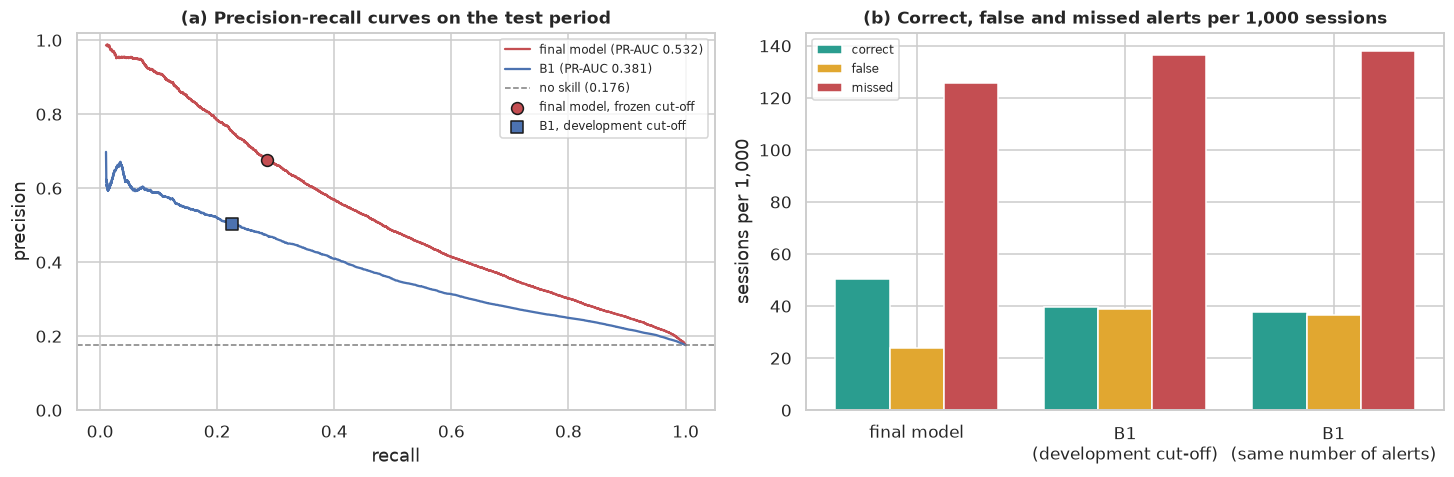

In [16]:
y_dev, s_dev, b_dev = OOF["y"].to_numpy(), OOF["score"].to_numpy(), OOF["b1"].to_numpy()
dev_rows = {
    "Final model, development (pooled)": (average_precision_score(y_dev, s_dev), s_dev >= CUT_OFF, y_dev),
    "Final model, test": (pr_final, flag_final, y_test),
    "B1, development (pooled)": (average_precision_score(y_dev, b_dev), b_dev >= B1_CUT, y_dev),
    "B1, test": (pr_b1, flag_b1, y_test),
}
dev_vs_test = pd.DataFrame([{"row": name, "abnormal share": y.mean(), "PR-AUC": pr, **confusion_metrics(y, flagged)} for name, (pr, flagged, y) in dev_rows.items()]).set_index("row")
display(dev_vs_test[["abnormal share"] + COLUMNS].style.format({**FMT, "abnormal share": "{:.1%}"}, na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
for name, score, color in [("final model", p_test, C_ABN), ("B1", b1_test, C_NORMAL)]:
    precision_c, recall_c, _ = precision_recall_curve(y_test, score)
    keep = recall_c > 0.01
    axes[0].plot(recall_c[keep], precision_c[keep], color=color, label=f"{name} (PR-AUC {average_precision_score(y_test, score):.3f})")
axes[0].axhline(y_test.mean(), color=C_GREY, ls="--", lw=1, label=f"no skill ({y_test.mean():.3f})")
for label, flagged, color, marker in [("final model, frozen cut-off", flag_final, C_ABN, "o"), ("B1, development cut-off", flag_b1, C_NORMAL, "s")]:
    m = confusion_metrics(y_test, flagged)
    axes[0].scatter(m["recall"], m["precision"], color=color, marker=marker, s=60, zorder=3, edgecolor="k", label=label)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].set_ylim(0, 1.02)
axes[0].set_title("(a) Precision-recall curves on the test period"); axes[0].legend(fontsize=8)
bar_rows = comparison.iloc[:3]
x = np.arange(3)
width = 0.26
for j, (col, color) in enumerate([("correct per 1,000", C_GREEN), ("false per 1,000", C_ORANGE), ("missed per 1,000", C_ABN)]):
    axes[1].bar(x + (j - 1) * width, bar_rows[col], width=width, color=color, label=col.replace(" per 1,000", ""))
axes[1].set_xticks(x); axes[1].set_xticklabels(["final model", "B1\n(development cut-off)", "B1\n(same number of alerts)"])
axes[1].set_ylabel("sessions per 1,000"); axes[1].set_title("(b) Correct, false and missed alerts per 1,000 sessions"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "05_1_final_vs_baseline")

Every measure of the final model is lower on the test than on the pooled development predictions: PR-AUC 0.635 against 0.532 (the mean of the folds is 0.626), precision 0.740 against 0.677, recall 0.403 against 0.286, F1 0.522 against 0.402, balanced accuracy 0.685 against 0.628 and MCC 0.479 against 0.373.
The alert rate falls from 10.0% to 7.4%. The number of false alerts per 1,000 sessions hardly changes (26.0 and 24.0), while the correct alerts fall from 74.0 to 50.3 and the missed sessions rise from 109.8 to 125.6. Fewer sessions reach the cut-off, and those that do are right slightly less often.

B1 falls too, and by more: its PR-AUC goes from 0.524 to 0.381 (−27%, against −16% for the final model) and its MCC from 0.378 to 0.251. The weakening is therefore not a defect of the fitted model alone. Section 6 asks how much of it is the abnormal share of the quarter (17.6% against 18.4%) and
how much is a change in the ranking. Figure (a) shows that the final model's precision-recall curve lies above that of B1 at every recall, and that both operating points sit on their curves.

In [17]:
final_row, b1_row = comparison.iloc[0], comparison.iloc[1]
log_decision("5", "Comparison with the baseline", "Reported as observed at the frozen operating points; no choice changes.",
             f"Test PR-AUC {pr_final:.4f} against {pr_b1:.4f} for B1 (gain {pr_final - pr_b1:+.4f}, 95% interval [{gain_ci[0]:+.4f}, {gain_ci[1]:+.4f}]); "
             f"at the frozen cut-off: precision {final_row['precision']:.3f}, recall {final_row['recall']:.3f}, F1 {final_row['F1']:.3f}, balanced accuracy "
             f"{final_row['balanced accuracy']:.3f}, MCC {final_row['MCC']:.3f}, alert rate {final_row['alert rate']:.2%}.")

---
## 6. Performance across time

The test result is one number for a whole quarter, and Section 5.3 showed that it is far from the development level. Here we ask when the change happened
and whether the model degrades inside the quarter. We use the same frozen cut-off everywhere and give, for each period, the abnormal share, the PR-AUC of the
final model and of B1, and the alert quality at the cut-off. A PR-AUC is shown only when a period has at least 30 abnormal sessions.

### 6.1 Development quarters and test months

In [18]:
test = test.assign(score=p_test, flag=flag_final, b1=b1_test, b1_flag=flag_b1)
MIN_POSITIVES = 30


def period_row(y, score, b1, flagged):
    y = np.asarray(y)
    ok = y.sum() >= MIN_POSITIVES and (1 - y).sum() > 0
    m = confusion_metrics(y, flagged)
    return {"sessions": len(y), "abnormal share": y.mean(), "PR-AUC final": average_precision_score(y, score) if ok else np.nan,
            "PR-AUC B1": average_precision_score(y, b1) if ok else np.nan, "ROC-AUC final": roc_auc_score(y, score) if ok else np.nan,
            "ROC-AUC B1": roc_auc_score(y, b1) if ok else np.nan, "alert rate": m["alert rate"], "precision": m["precision"],
            "recall": m["recall"], "F1": m["F1"], "false per 1,000": m["false per 1,000"], "missed per 1,000": m["missed per 1,000"]}


rows = {}
for f in FOLDS:
    g = OOF[OOF["fold"] == f["fold"]]
    rows[f"fold {f['fold']}: {f['lo'].date()} to {(f['hi'] - pd.Timedelta(days=1)).date()} (development)"] = period_row(g["y"], g["score"], g["b1"], g["score"] >= CUT_OFF)
test_months = test["start_time"].dt.to_period("M")
for month, g in test.groupby(test_months):
    rows[f"test {month}"] = period_row(g[TARGET], g["score"], g["b1"], g["flag"])
rows["test, whole period"] = period_row(test[TARGET], test["score"], test["b1"], test["flag"])
time_table = pd.DataFrame(rows).T
TIME_FMT = {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "PR-AUC final": "{:.4f}", "PR-AUC B1": "{:.4f}", "ROC-AUC final": "{:.3f}", "ROC-AUC B1": "{:.3f}",
            "alert rate": "{:.1%}", "precision": "{:.3f}",
            "recall": "{:.3f}", "F1": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}
time_table["lift final"] = time_table["PR-AUC final"] / time_table["abnormal share"]
time_table["lift B1"] = time_table["PR-AUC B1"] / time_table["abnormal share"]
display(time_table.style.format({**TIME_FMT, "lift final": "{:.2f}", "lift B1": "{:.2f}"}, na_rep="—"))

# How much of the fall from fold 4 to the test is the lower abnormal share? PR-AUC moves with the abnormal share, so we keep the lift of fold 4 and apply it to the test share.
f4, tst = time_table.iloc[3], time_table.loc["test, whole period"]
expected = f4["lift final"] * tst["abnormal share"]
total_fall = f4["PR-AUC final"] - tst["PR-AUC final"]
print(f"PR-AUC fell by {total_fall:.4f} from fold 4 ({f4['PR-AUC final']:.4f}) to the test ({tst['PR-AUC final']:.4f}). With the lift of fold 4 ({f4['lift final']:.2f}) and the test share "
      f"({tst['abnormal share']:.1%}) the expected PR-AUC is {expected:.4f}: {f4['PR-AUC final'] - expected:.4f} of the fall ({(f4['PR-AUC final'] - expected) / total_fall:.0%}) comes from the lower abnormal share "
      f"and {expected - tst['PR-AUC final']:.4f} ({(expected - tst['PR-AUC final']) / total_fall:.0%}) from the lower lift. ROC-AUC, which does not depend on the share: fold 4 {f4['ROC-AUC final']:.3f}, test {tst['ROC-AUC final']:.3f}.")
FALL_SPLIT = {"total fall": float(total_fall), "from the abnormal share": float(f4["PR-AUC final"] - expected), "from the lift": float(expected - tst["PR-AUC final"])}

,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",lift final,lift B1
fold 1: 2020-10-01 to 2020-12-31 (development),"60,364",16.8%,0.6176,0.4991,0.835,0.764,8.4%,0.751,0.375,0.500,21.0,105.2,3.67,2.96
fold 2: 2021-01-01 to 2021-03-31 (development),"41,797",15.8%,0.5755,0.4562,0.825,0.749,7.7%,0.713,0.347,0.467,22.1,103.3,3.64,2.88
fold 3: 2021-04-01 to 2021-06-30 (development),"57,542",18.2%,0.6497,0.5466,0.844,0.789,10.4%,0.739,0.423,0.538,27.2,105.1,3.56,3.00
fold 4: 2021-07-01 to 2021-09-30 (development),"75,769",21.1%,0.6604,0.5403,0.838,0.788,12.2%,0.745,0.430,0.545,31.1,120.6,3.12,2.56
test 2021-10,"27,794",18.6%,0.5534,0.4020,0.792,0.723,8.5%,0.694,0.315,0.434,25.8,127.3,2.98,2.16
test 2021-11,"25,669",16.5%,0.4832,0.3322,0.784,0.711,6.0%,0.637,0.232,0.340,21.8,126.7,2.93,2.01
test 2021-12,"26,618",17.6%,0.5511,0.3961,0.803,0.733,7.7%,0.687,0.301,0.419,24.2,122.9,3.13,2.25
"test, whole period","80,081",17.6%,0.5324,0.3809,0.794,0.723,7.4%,0.677,0.286,0.402,24.0,125.6,3.03,2.17


PR-AUC fell by 0.1280 from fold 4 (0.6604) to the test (0.5324). With the lift of fold 4 (3.12) and the test share (17.6%) the expected PR-AUC is 0.5496: 0.1108 of the fall (87%) comes from the lower abnormal share and 0.0172 (13%) from the lower lift. ROC-AUC, which does not depend on the share: fold 4 0.838, test 0.794.


Read on its own, PR-AUC makes the test look much worse than any development quarter: the final model scores 0.553, 0.483 and 0.551 in the three test months, and 0.5755 in its worst development fold. But PR-AUC rises with the abnormal share, which was 21.1% in fold 4 and is 17.6% in the test. With the lift of fold 4
(3.12) applied to the test share, the expected PR-AUC would be 0.5496, so 0.1108 of the 0.1280 fall from fold 4 (87%) is the lower abnormal share and only 0.0172 (13%) comes from the lower lift. Part of the drop that Task 4 reported is therefore arithmetic, which is why Task 2 asks for the lift and the share to be read with
the score.

The ranking did weaken, though. The ROC-AUC, which does not depend on the abnormal share, is 0.794 on the test (0.792, 0.784 and 0.803 by month), below the four development folds (0.825 to 0.844), and the lift of the whole test (3.03) is below every development fold (3.12 to 3.67). The lift had already been falling in development (3.67, 3.64, 3.56, 3.12), so the test continues a gradual decline rather
than a sudden break. B1 loses more: its lift goes from 2.56 in fold 4 to 2.17 and its ROC-AUC from 0.788 to 0.723, against a fall of 0.09 in lift and 0.044 in ROC-AUC for the final model. At the frozen cut-off the alert rate follows the abnormal share and the scores (6.0% in November, 8.5% in October), the precision stays between 0.637 and 0.694 (0.713 to 0.751 in development) and the recall between 0.232 and 0.315 (0.347 to 0.430).
November is the weakest month on every measure: the lowest abnormal share of the three (16.5%), PR-AUC 0.483 and recall 0.232.

### 6.2 Week by week inside the test period

Months hide a change that happens within a month, so the next table and figure follow the 13 weeks of the test period (weeks start on Monday, so the first and the
last are partial). We want to see whether the weakening is gradual or sudden, and whether the number of alerts follows the number of failures.

,sessions,abnormal share,PR-AUC final,PR-AUC B1,alert rate,precision,recall
2021-09-27,"3,209",23.7%,0.6421,0.5515,14.8%,0.687,0.429
2021-10-04,"6,083",20.0%,0.6005,0.4334,10.0%,0.730,0.365
2021-10-11,"6,318",17.2%,0.4933,0.3070,7.0%,0.649,0.265
2021-10-18,"6,268",17.6%,0.5436,0.4206,7.1%,0.718,0.288
2021-10-25,"5,916",16.8%,0.4832,0.3186,6.4%,0.671,0.254
2021-11-01,"5,435",15.4%,0.4129,0.2779,5.3%,0.566,0.194
2021-11-08,"6,212",16.4%,0.4869,0.3285,5.6%,0.653,0.224
2021-11-15,"6,043",16.0%,0.4683,0.3300,5.4%,0.609,0.206
2021-11-22,"6,309",18.1%,0.5404,0.3884,7.6%,0.695,0.291
2021-11-29,"6,359",17.3%,0.5453,0.3976,7.2%,0.692,0.288


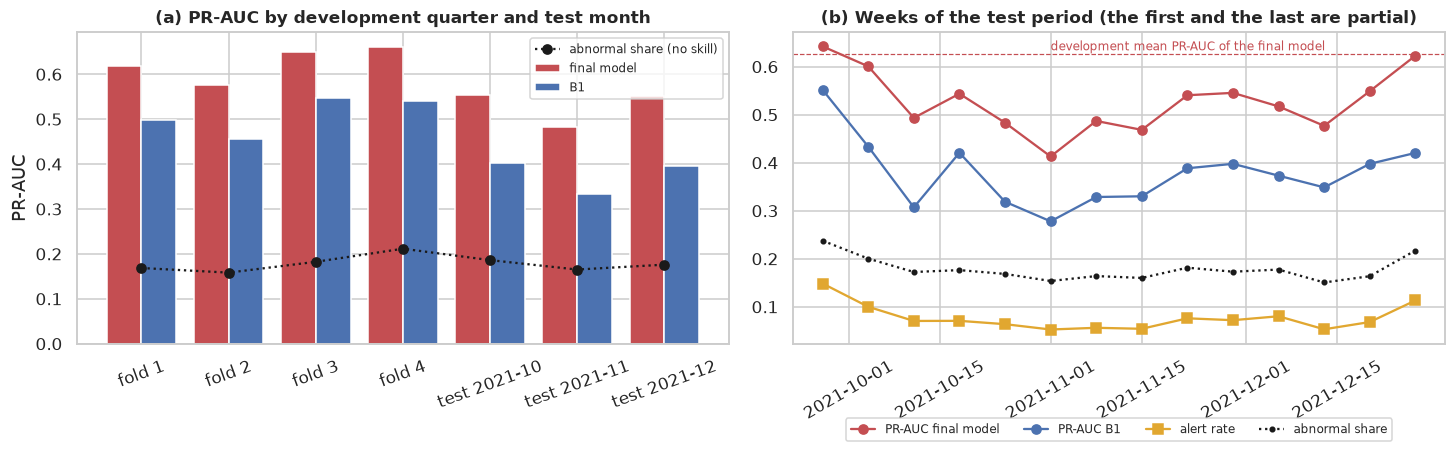

In [19]:
week = test["start_time"].dt.to_period("W-SUN").dt.start_time
weekly = pd.DataFrame({w: period_row(g[TARGET], g["score"], g["b1"], g["flag"]) for w, g in test.groupby(week)}).T
weekly.index = [d.date() for d in weekly.index]
display(weekly[["sessions", "abnormal share", "PR-AUC final", "PR-AUC B1", "alert rate", "precision", "recall"]].style.format(TIME_FMT, na_rep="—"))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
labels = [f"fold {f['fold']}" for f in FOLDS] + [str(m) for m in time_table.index[4:7]]
vals = time_table.iloc[:7]
x = np.arange(len(vals))
axes[0].bar(x - 0.2, vals["PR-AUC final"], width=0.4, color=C_ABN, label="final model")
axes[0].bar(x + 0.2, vals["PR-AUC B1"], width=0.4, color=C_NORMAL, label="B1")
axes[0].plot(x, vals["abnormal share"], color="k", marker="o", ls=":", label="abnormal share (no skill)")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=20); axes[0].set_ylabel("PR-AUC")
axes[0].set_title("(a) PR-AUC by development quarter and test month"); axes[0].legend(fontsize=8)
wk = weekly.index
axes[1].plot(wk, weekly["PR-AUC final"], color=C_ABN, marker="o", label="PR-AUC final model")
axes[1].plot(wk, weekly["PR-AUC B1"], color=C_NORMAL, marker="o", label="PR-AUC B1")
axes[1].plot(wk, weekly["alert rate"], color=C_ORANGE, marker="s", label="alert rate")
axes[1].plot(wk, weekly["abnormal share"], color="k", ls=":", marker=".", label="abnormal share")
axes[1].axhline(FROZEN["development_estimates"]["PR-AUC mean"], color=C_ABN, ls="--", lw=0.8)
axes[1].text(wk[5], FROZEN["development_estimates"]["PR-AUC mean"] + 0.008, "development mean PR-AUC of the final model", fontsize=8, color=C_ABN)
axes[1].set_title("(b) Weeks of the test period (the first and the last are partial)"); axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
fig.tight_layout()
savefig(fig, "06_1_performance_over_time")

The weekly PR-AUC of the final model runs from 0.413 (week of 1 November) to 0.642 in the first, partial week (1 to 3 October), and 0.623 in the last partial week. The two partial weeks have the highest abnormal shares (23.7% and 21.7%) and the highest alert rates (14.8% and 11.3%), and the weeks with a share
below 17% have a PR-AUC between 0.41 and 0.55. The weekly curves of the model and of B1 move together, and they follow the abnormal share, which is the reading of Section 6.1. We see no downward drift inside the quarter: the lowest weeks are at the end of October and the beginning of November, and the model recovers in the second half of November (0.540 and 0.545), before falling again in mid-December (0.477). The alert rate goes from 5.3% to 14.8% by week (Section 10.1 gives the daily range), so the workload of an operator will change from week to week with the failures. Each weekly point rests on about 1,000 abnormal sessions, so differences of a few hundredths between weeks are within noise.

---
## 7. Performance across operational groups

The operator acts on districts, stations and charging posts, so a model that works on average could still fail for some of them. For each group we report the
same measures as above at the frozen cut-off, the PR-AUC of the final model and of B1, and the alert rate. A group is shown with a PR-AUC only when it has
at least 30 abnormal sessions.

### 7.1 Districts and stations

In [20]:
def group_table(frame, key):
    rows = {name: period_row(g[TARGET], g["score"], g["b1"], g["flag"]) for name, g in frame.groupby(key)}
    t = pd.DataFrame(rows).T
    t["gain over B1"] = t["PR-AUC final"] - t["PR-AUC B1"]
    return t


GROUP_FMT = {**TIME_FMT, "gain over B1": "{:+.4f}"}
district_table = group_table(test, "district")
station_table = group_table(test, "location").sort_values("PR-AUC final", ascending=False)
print("Districts")
display(district_table.style.format(GROUP_FMT, na_rep="—"))
print("Stations (sorted by PR-AUC of the final model)")
display(station_table.style.format(GROUP_FMT, na_rep="—"))
print(f"Stations: {len(station_table)} | abnormal share from {station_table['abnormal share'].min():.1%} to {station_table['abnormal share'].max():.1%} | "
      f"PR-AUC of the final model from {station_table['PR-AUC final'].min():.3f} to {station_table['PR-AUC final'].max():.3f} | "
      f"final model above B1 in {(station_table['gain over B1'] > 0).sum()} of {station_table['gain over B1'].notna().sum()} stations")

Districts


,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
Nanhu,"10,891",23.9%,0.5767,0.3879,0.770,0.665,11.0%,0.693,0.320,0.438,33.9,162.2,+0.1887
Tongxiang,"38,337",12.0%,0.4743,0.3300,0.803,0.722,3.8%,0.706,0.224,0.341,11.3,93.3,+0.1443
Xiuzhou,"30,853",22.3%,0.5524,0.3999,0.759,0.683,10.6%,0.658,0.314,0.425,36.3,153.0,+0.1525


Stations (sorted by PR-AUC of the final model)


,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
Expressway Service District B,"3,295",22.9%,0.6299,0.3691,0.780,0.652,14.5%,0.705,0.446,0.546,42.8,127.2,+0.2608
Tourist Attraction,"7,313",27.1%,0.6143,0.4111,0.772,0.650,13.3%,0.710,0.349,0.468,38.7,176.4,+0.2032
Expressway Service District C,"10,908",27.3%,0.5954,0.4642,0.743,0.682,15.5%,0.655,0.372,0.475,53.6,171.4,+0.1312
Shopping Mall,"9,529",19.5%,0.5763,0.4184,0.774,0.693,8.8%,0.749,0.337,0.465,21.9,129.1,+0.1579
Expressway Service District A,"3,654",18.6%,0.5644,0.2956,0.751,0.624,9.6%,0.728,0.374,0.494,26.0,116.3,+0.2688
Park A,"4,322",23.0%,0.5034,0.4207,0.737,0.688,8.8%,0.624,0.238,0.345,33.1,175.2,+0.0826
Wholesale Market,"6,763",24.7%,0.4670,0.3773,0.695,0.642,8.0%,0.587,0.190,0.287,33.1,200.2,+0.0897
Financial Industrial Park,"3,578",17.2%,0.4343,0.2881,0.734,0.639,6.3%,0.618,0.226,0.331,24.0,133.0,+0.1462
Government Agency,"6,233",12.7%,0.4126,0.2592,0.780,0.678,3.4%,0.651,0.177,0.278,12.0,104.6,+0.1534
Industrial Park,"3,819",6.8%,0.3728,0.1175,0.796,0.628,1.2%,0.787,0.143,0.243,2.6,57.9,+0.2553


Stations: 12 | abnormal share from 6.8% to 27.3% | PR-AUC of the final model from 0.251 to 0.630 | final model above B1 in 12 of 12 stations


The model is above B1 in all three districts (gains of +0.144 to +0.189) and in all 12 stations that appear in the test (+0.083 to +0.269), so it improves on the baseline everywhere. Its quality still varies a lot. Tongxiang holds 47.9% of the sessions but has a low abnormal share (12.0%), and there the model
flags 3.8% of the sessions and catches 22.4% of the failures (PR-AUC 0.474), while Nanhu and Xiuzhou (23.9% and 22.3% abnormal) have PR-AUC of 0.577 and 0.552, alert rates of about 11% and recalls of 0.32 and 0.31. The precision of the alerts is similar in the three districts (0.658 to 0.706), but the false alerts per 1,000 sessions are
three times higher in Nanhu and Xiuzhou (33.9 and 36.3) than in Tongxiang (11.3), because that is where the alerts are.

Among stations, the PR-AUC runs from 0.251 (Park B) to 0.630 (Expressway Service District B). The three stations with the lowest abnormal share (Industrial Park 6.8%, Park B 7.1% and Bus Station 7.4%) are the three with the lowest PR-AUC, and there the model is almost silent: alert rates of 0.6% to 1.3% and recalls of 0.04 to 0.14.
Their lift is high (about 3.5 to 5.5), so the alerts that it raises there are well placed, but it finds very few of the failures. The raw PR-AUC of a station should be read with its abnormal share, as in Section 6.

### 7.2 Charging posts

There are 92 posts, so a table of all of them would be long. We summarise them in three ways: how the alerts and the abnormal sessions are spread over the posts, the ten
posts that receive the most alerts, and how precision and recall vary between posts with enough sessions (at least 200 test sessions, and at least 20 alerts for the
precision or 30 abnormal sessions for the recall). The post identifier is used only to group results, never as a predictor.

,sessions,abnormal,alerts,TP,abnormal share,alert rate,precision,recall
post_id,,,,,,,,
27,"1,338",618,506,417,46.2%,37.8%,0.824,0.675
83,"1,816",718,428,229,39.5%,23.6%,0.535,0.319
81,"1,450",507,372,288,35.0%,25.7%,0.774,0.568
32,731,389,311,203,53.2%,42.5%,0.653,0.522
78,"1,278",432,269,212,33.8%,21.0%,0.788,0.491
89,802,382,256,164,47.6%,31.9%,0.641,0.429
77,"1,731",378,236,159,21.8%,13.6%,0.674,0.421
4,668,294,197,148,44.0%,29.5%,0.751,0.503
5,973,269,186,165,27.6%,19.1%,0.887,0.613


,value
posts,88.000
posts with at least one alert,88.000
top 10% of posts by alerts,9.000
their share of all alerts,0.464
their share of all abnormal sessions,0.283
their share of all sessions,0.135
"Spearman, post abnormal share vs alert rate",0.909


Precision at the frozen cut-off across 44 posts: min 0.312, median 0.654, max 0.887
Recall across 80 posts: min 0.000, median 0.142, max 0.675


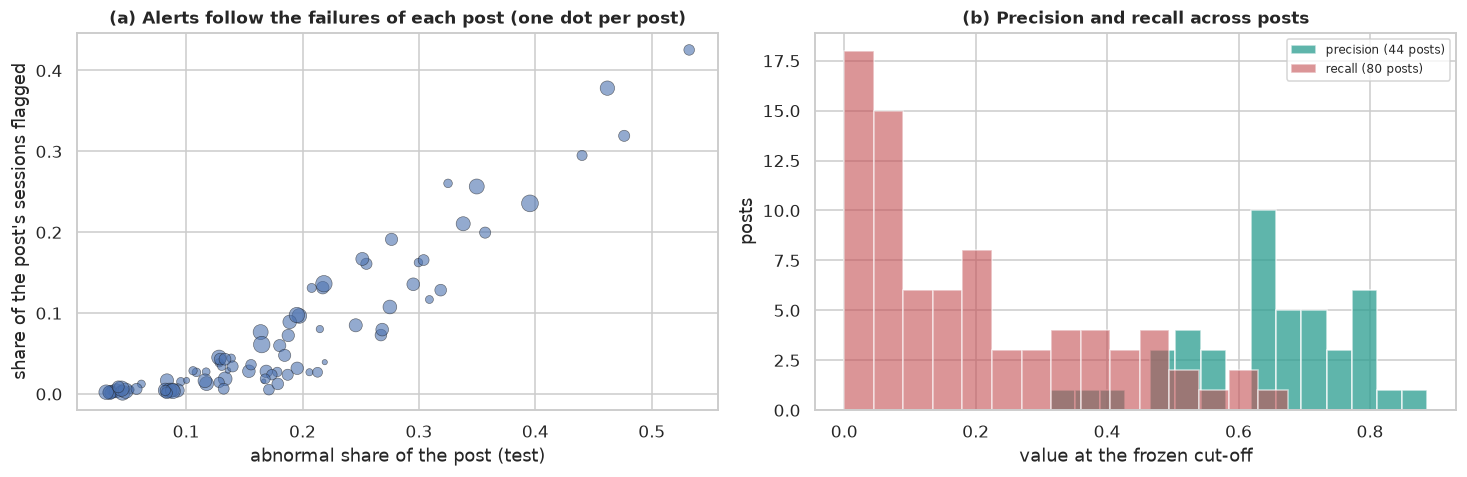

In [21]:
test["post_id"] = test["post_id"].astype(str)
by_post = test.groupby("post_id").apply(
    lambda g: pd.Series({"sessions": len(g), "abnormal": int(g[TARGET].sum()), "alerts": int(g["flag"].sum()), "TP": int((g["flag"] & (g[TARGET] == 1)).sum())}),
    include_groups=False)
by_post["abnormal share"] = by_post["abnormal"] / by_post["sessions"]
by_post["alert rate"] = by_post["alerts"] / by_post["sessions"]
by_post["precision"] = by_post["TP"] / by_post["alerts"].where(by_post["alerts"] > 0)
by_post["recall"] = by_post["TP"] / by_post["abnormal"].where(by_post["abnormal"] > 0)
top_posts = by_post.sort_values("alerts", ascending=False).head(10)
display(top_posts.style.format({"sessions": "{:,.0f}", "abnormal": "{:,.0f}", "alerts": "{:,.0f}", "TP": "{:,.0f}", "abnormal share": "{:.1%}", "alert rate": "{:.1%}",
                                "precision": "{:.3f}", "recall": "{:.3f}"}, na_rep="—"))

sorted_alerts = by_post["alerts"].sort_values(ascending=False)
n_top = max(1, int(round(0.1 * len(by_post))))
top10 = by_post.loc[sorted_alerts.index[:n_top]]
concentration = {"posts": len(by_post), "posts with at least one alert": int((by_post["alerts"] > 0).sum()), "top 10% of posts by alerts": n_top,
                 "their share of all alerts": float(top10["alerts"].sum() / by_post["alerts"].sum()),
                 "their share of all abnormal sessions": float(top10["abnormal"].sum() / by_post["abnormal"].sum()),
                 "their share of all sessions": float(top10["sessions"].sum() / by_post["sessions"].sum())}
rho = spearmanr(by_post["abnormal share"], by_post["alert rate"])
concentration["Spearman, post abnormal share vs alert rate"] = float(rho.statistic)
display(pd.Series(concentration, name="value").to_frame().style.format(lambda v: f"{v:.3f}" if isinstance(v, float) else f"{v}"))

big = by_post[by_post["sessions"] >= 200]
prec_posts, rec_posts = big[big["alerts"] >= 20]["precision"].dropna(), big[big["abnormal"] >= 30]["recall"].dropna()
print(f"Precision at the frozen cut-off across {len(prec_posts)} posts: min {prec_posts.min():.3f}, median {prec_posts.median():.3f}, max {prec_posts.max():.3f}")
print(f"Recall across {len(rec_posts)} posts: min {rec_posts.min():.3f}, median {rec_posts.median():.3f}, max {rec_posts.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
axes[0].scatter(by_post["abnormal share"], by_post["alert rate"], s=by_post["sessions"] / 15, color=C_NORMAL, alpha=0.6, edgecolor="k", lw=0.4)
axes[0].set_xlabel("abnormal share of the post (test)"); axes[0].set_ylabel("share of the post's sessions flagged")
axes[0].set_title("(a) Alerts follow the failures of each post (one dot per post)")
axes[1].hist(prec_posts, bins=15, color=C_GREEN, alpha=0.75, label=f"precision ({len(prec_posts)} posts)")
axes[1].hist(rec_posts, bins=15, color=C_ABN, alpha=0.6, label=f"recall ({len(rec_posts)} posts)")
axes[1].set_xlabel("value at the frozen cut-off"); axes[1].set_ylabel("posts"); axes[1].set_title("(b) Precision and recall across posts"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "07_1_posts")

The 88 posts that appear in the test period all receive at least one alert. The alerts are concentrated: the nine posts with the most alerts (10% of the posts) receive 46.4% of them, hold 28.3% of the abnormal sessions and 13.5% of all sessions, and the Spearman correlation between the abnormal share of a post and its alert rate is 0.909 (figure a).
The model sends its alerts to the posts that are failing most, which agrees with the dominance of the post history in Section 9. At the busiest posts the alerts work well, for instance post 27 (506 alerts, precision 0.824, recall 0.675), but not everywhere: post 83 has 428 alerts with a precision of 0.535 and a recall of 0.319.

Across the 44 posts with at least 20 alerts the precision at the frozen cut-off goes from 0.312 to 0.887 (median 0.654). The recall is the weak point: across the 80 posts with at least 30 abnormal sessions the median is 0.142, the maximum 0.675, and figure (b) shows a large group of posts with a recall close to zero. The model identifies which posts are failing at the moment, but
it finds few of the failures at the other posts.

### 7.3 New and returning users

Task 2 flagged the cold start as an assumption: the user-history group needs an identified account, and new accounts have no history. The next table checks the
final model on the two kinds of session.

In [22]:
test["user type"] = np.where(test["is_new_user"] == 1, "new user", "returning user")
user_table = group_table(test, "user type")
display(user_table.style.format(GROUP_FMT, na_rep="—"))

,sessions,abnormal share,PR-AUC final,PR-AUC B1,ROC-AUC final,ROC-AUC B1,alert rate,precision,recall,F1,"false per 1,000","missed per 1,000",gain over B1
new user,"10,353",17.6%,0.3939,0.3209,0.692,0.676,4.0%,0.639,0.146,0.237,14.5,150.3,+0.0730
returning user,"69,728",17.6%,0.5513,0.3922,0.806,0.730,7.9%,0.680,0.307,0.423,25.4,122.0,+0.1591


New users are 12.9% of the test sessions and the model works clearly worse for them: PR-AUC of 0.394 against 0.551 for returning users, recall of 0.146 against 0.307 and alert rate of 4.0% against 7.9%. The precision of the alerts is similar (0.639 and 0.680), so the model is not wrong more often for new users, it simply
raises fewer alerts because it has no user history to rely on (Section 9 shows how much it uses that group). It still beats B1 for new users, by +0.073 against +0.159 for returning users. This is the cold-start limit that Task 2 anticipated, and a possible reason to give these sessions a different treatment.

In [23]:
log_decision("6-7", "Time and group analysis", "Descriptive only: the frozen cut-off is applied everywhere and no group-specific threshold is introduced.",
             f"Test months PR-AUC {time_table.loc['test 2021-10', 'PR-AUC final']:.3f}, {time_table.loc['test 2021-11', 'PR-AUC final']:.3f}, {time_table.loc['test 2021-12', 'PR-AUC final']:.3f}; "
             f"districts {len(district_table)}, stations {len(station_table)}, posts {len(by_post)}.")

---
## 8. Error analysis

At the frozen cut-off every test session falls in one of four classes: a *true positive* (an alert on an abnormal session), a *false positive* (an alert on a normal
session), a *false negative* (an abnormal session without an alert) and a *true negative*. We look for patterns in the two kinds of error. The end cause of a session
is used here only to describe which failures are missed; it is a post-session variable and was never a predictor. As in Sections 6 and 7, the analysis is descriptive
and cannot change a frozen choice.

### 8.1 The four classes and the failures that are missed

In [24]:
err = test.copy()
y_bool = err[TARGET].to_numpy().astype(bool)
err["outcome"] = np.select([err["flag"] & y_bool, err["flag"] & ~y_bool, ~err["flag"] & y_bool], ["TP", "FP", "FN"], "TN")
outcome_counts = err["outcome"].value_counts().reindex(["TP", "FP", "FN", "TN"])
display(pd.DataFrame({"sessions": outcome_counts, "per 1,000 sessions": 1000 * outcome_counts / len(err), "share of the abnormal sessions": outcome_counts / y_bool.sum() * [1, np.nan, 1, np.nan],
                      "share of the alerts": outcome_counts / err["flag"].sum() * [1, 1, np.nan, np.nan]}).style.format(
    {"sessions": "{:,.0f}", "per 1,000 sessions": "{:.1f}", "share of the abnormal sessions": "{:.1%}", "share of the alerts": "{:.1%}"}, na_rep="—"))

abnormal = err[err[TARGET] == 1]
cause_table = abnormal.groupby("end_cause").agg(sessions=("flag", "size"), detected=("flag", "sum"), mean_score=("score", "mean"))
cause_table["recall"] = cause_table["detected"] / cause_table["sessions"]
cause_table["share of all abnormal"] = cause_table["sessions"] / cause_table["sessions"].sum()
cause_table["share of all missed"] = (cause_table["sessions"] - cause_table["detected"]) / (cause_table["sessions"] - cause_table["detected"]).sum()
cause_table = cause_table.sort_values("sessions", ascending=False).rename(columns={"mean_score": "mean score"})
display(cause_table.style.format({"sessions": "{:,.0f}", "detected": "{:,.0f}", "mean score": "{:.3f}", "recall": "{:.3f}", "share of all abnormal": "{:.1%}", "share of all missed": "{:.1%}"}))
print(f"End causes among the abnormal test sessions: {len(cause_table)} | overall recall {cause_table['detected'].sum() / cause_table['sessions'].sum():.3f}")

,sessions,"per 1,000 sessions",share of the abnormal sessions,share of the alerts
outcome,,,,
TP,"4,026",50.3,28.6%,67.7%
FP,"1,921",24.0,—,32.3%
FN,"10,062",125.6,71.4%,—
TN,"64,072",800.1,—,—


,sessions,detected,mean score,recall,share of all abnormal,share of all missed
end_cause,,,,,,
Other faults of the charging pile,"3,197","1,083",0.395,0.339,22.7%,21.0%
Vehicle communications failure,"2,316",745,0.381,0.322,16.4%,15.6%
DC Output Fault,"2,226",444,0.304,0.199,15.8%,17.7%
Vehicle charging faults,"1,661",620,0.425,0.373,11.8%,10.3%
BMS failure,"1,586",313,0.282,0.197,11.3%,12.7%
Faulty charging connection,"1,525",335,0.316,0.220,10.8%,11.8%
Failure of non-system control loop components and assemblies,818,157,0.268,0.192,5.8%,6.6%
DC switching device failure,467,235,0.475,0.503,3.3%,2.3%
Power conversion unit failure,259,80,0.375,0.309,1.8%,1.8%


End causes among the abnormal test sessions: 12 | overall recall 0.286


At the frozen cut-off the test has 4,026 true positives, 1,921 false positives, 10,062 false negatives and 64,072 true negatives. A third of the alerts (32.3%) are false, and 71.4% of the abnormal sessions go without an alert. By end cause (12 of the 13 causes appear in the test), the recall goes from 0.192 to 0.503. The causes
best detected are the DC switching device failure (recall 0.503, 467 sessions), the vehicle charging faults (0.373, 1,661) and the other faults of the charging pile (0.339, 3,197). The least detected are the failure of non-system control loop components (0.192, 818), the BMS failure (0.197, 1,586), the DC output fault (0.199, 2,226) and the faulty charging
connection (0.220, 1,525): four causes that make up 43.7% of the abnormal sessions but 48.8% of the missed ones. The three causes with fewer than 20 sessions give recalls that mean nothing. We do not read causal meaning into the differences, because the model never sees the cause. A likely reading is that some faults tend to come in bursts at a post that has just failed, which the model sees, and others
tend to appear alone.

### 8.2 Who is flagged and who is missed

The next table gives the typical value of the main variables in each of the four classes (median for numeric variables, share for the two indicators). It shows what
separates the false positives from the true positives, and the missed failures from the failures that the model finds.

In [25]:
profile_vars = ["score", "post_previous_abnormal_rate_1D", "post_previous_abnormal_rate_7D", "post_previous_abnormal_rate_30D", "post_previous_sessions_7D",
                "post_hours_since_previous_completed_abnormal", "user_previous_abnormal_rate_180D", "user_previous_sessions_180D", "user_active_sessions_at_start",
                "temperature", "hour"]
profile = pd.DataFrame({cls: err[err["outcome"] == cls][profile_vars].median() for cls in ["TP", "FP", "FN", "TN"]})
for col in ["is_new_user", "rain_flag"]:
    profile.loc[f"share with {col}"] = [err[err["outcome"] == cls][col].mean() for cls in ["TP", "FP", "FN", "TN"]]
profile.loc["share without a previous abnormal session at the post"] = [err[err["outcome"] == cls]["post_hours_since_previous_completed_abnormal"].isna().mean() for cls in ["TP", "FP", "FN", "TN"]]
profile.loc["sessions"] = [int((err["outcome"] == cls).sum()) for cls in ["TP", "FP", "FN", "TN"]]
display(profile.style.format("{:.3f}", na_rep="—"))

,TP,FP,FN,TN
score,0.701,0.574,0.188,0.094
post_previous_abnormal_rate_1D,0.487,0.364,0.182,0.125
post_previous_abnormal_rate_7D,0.404,0.333,0.184,0.125
post_previous_abnormal_rate_30D,0.331,0.325,0.189,0.132
post_previous_sessions_7D,101.000,91.000,85.000,88.000
post_hours_since_previous_completed_abnormal,0.024,0.025,6.929,14.814
user_previous_abnormal_rate_180D,0.333,0.333,0.200,0.167
user_previous_sessions_180D,7.000,6.000,12.000,17.000
user_active_sessions_at_start,0.000,0.000,0.000,0.000
temperature,12.900,13.700,13.200,13.100


The false positives look like the true positives, and the false negatives look like the true negatives. The median score is 0.701 for the true positives and 0.574 for the false positives, against 0.188 for the false negatives and 0.094 for the true negatives. The reason is the post history: the median time since the last abnormal session of the post is
0.024 and 0.025 hours (about a minute and a half) for the true positives and the false positives, 6.9 hours for the false negatives and 14.8 hours for the true negatives, and the abnormal rate of the post in the last day is 0.487 and 0.364 for the two kinds of alert but only 0.182 for the missed failures. A session that starts moments after a failure at its post is flagged, and
whether it fails too decides if the alert is true or false, which the model cannot tell. The failures that the model misses are the ones that begin at posts that have been quiet for hours. The user also matters: the missed failures have more experienced users (median 12 sessions in the last 180 days against 7 and 6 for the two kinds of alert), a lower abnormal rate of the user (0.200 against 0.333) and more new users (15.5% against 6.6% for the true positives).
Hour, temperature and rain do not separate the classes (median hour 14 in all four, temperature 12.9 to 13.7 °C, share with rain 24% to 28%).

### 8.3 Where the errors concentrate

For each band of a variable the table gives the abnormal share, the alert rate, the precision and recall at the frozen cut-off, the false alerts and missed abnormal
sessions per 1,000 sessions of the band, and the share of all false alerts and of all missed failures that the band holds. A band that holds a larger share of the
errors than of the sessions is a pattern to explain.

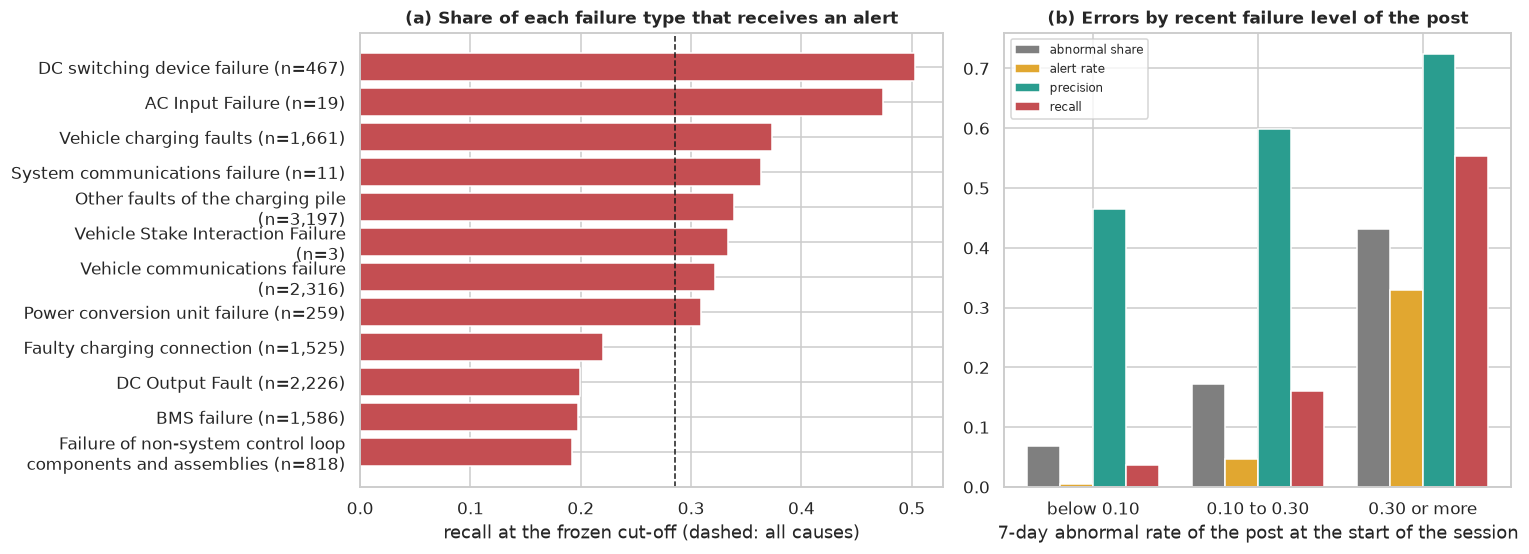

In [26]:
hours_since = err["post_hours_since_previous_completed_abnormal"]
BANDS = {
    "post failure rate, last 7 days": pd.cut(err["post_previous_abnormal_rate_7D"], [-np.inf, 0.10, 0.30, np.inf], right=False, labels=["below 0.10", "0.10 to 0.30", "0.30 or more"]),
    "post failure rate, last day": pd.cut(err["post_previous_abnormal_rate_1D"], [-np.inf, 0.10, 0.30, np.inf], right=False, labels=["below 0.10", "0.10 to 0.30", "0.30 or more"]),
    "time since the post's last abnormal session": pd.cut(hours_since, [-np.inf, 6, 24, 168, np.inf], right=False,
                                                         labels=["under 6 h", "6 to 24 h", "1 to 7 days", "over 7 days"]).cat.add_categories("none recorded").fillna("none recorded"),
    "user": pd.Series(np.where(err["is_new_user"] == 1, "new user", "returning user"), index=err.index),
    "hour of the day": pd.cut(err["hour"], [-1, 5, 11, 17, 23], labels=["00 to 05", "06 to 11", "12 to 17", "18 to 23"]),
    "day type": pd.Series(np.where(err["dow"] >= 5, "weekend", "weekday"), index=err.index),
    "weather": pd.Series(np.where(err["rain_flag"] == 1, "rain", "dry"), index=err.index),
    "district": err["district"],
}
total_fp, total_fn = int((err["outcome"] == "FP").sum()), int((err["outcome"] == "FN").sum())
rows = []
for variable, band_series in BANDS.items():
    for band, g in err.groupby(band_series, observed=True):
        m = confusion_metrics(g[TARGET], g["flag"])
        rows.append({"variable": variable, "band": band, "sessions": len(g), "share of sessions": len(g) / len(err), "abnormal share": g[TARGET].mean(),
                     "alert rate": m["alert rate"], "precision": m["precision"], "recall": m["recall"], "false per 1,000": m["false per 1,000"],
                     "missed per 1,000": m["missed per 1,000"], "share of all false alerts": m["FP"] / total_fp, "share of all missed": m["FN"] / total_fn})
band_table = pd.DataFrame(rows).set_index(["variable", "band"])
display(band_table.style.format({"sessions": "{:,.0f}", "share of sessions": "{:.1%}", "abnormal share": "{:.1%}", "alert rate": "{:.1%}", "precision": "{:.3f}",
                                 "recall": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}", "share of all false alerts": "{:.1%}", "share of all missed": "{:.1%}"}, na_rep="—"))

import textwrap
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
c = cause_table.sort_values("recall")
axes[0].barh(["\n".join(textwrap.wrap(f"{i} (n={int(n):,})", 38)) for i, n in zip(c.index, c["sessions"])], c["recall"], color=C_ABN)
axes[0].axvline(cause_table["detected"].sum() / cause_table["sessions"].sum(), color="k", ls="--", lw=1)
axes[0].set_xlabel("recall at the frozen cut-off (dashed: all causes)"); axes[0].set_title("(a) Share of each failure type that receives an alert")
bt = band_table.loc["post failure rate, last 7 days"]
x = np.arange(len(bt))
for j, (col, color) in enumerate([("abnormal share", C_GREY), ("alert rate", C_ORANGE), ("precision", C_GREEN), ("recall", C_ABN)]):
    axes[1].bar(x + (j - 1.5) * 0.2, bt[col], width=0.2, color=color, label=col)
axes[1].set_xticks(x); axes[1].set_xticklabels(bt.index); axes[1].set_xlabel("7-day abnormal rate of the post at the start of the session")
axes[1].set_title("(b) Errors by recent failure level of the post"); axes[1].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "08_1_error_analysis")

The errors follow how recently the post has failed. When the 7-day abnormal rate of the post is 0.30 or more (14.7% of the sessions, 43.2% abnormal), the model flags 33.0% of them with a precision of 0.723 and a recall of 0.553. Below 0.10 (33.3% of the sessions) it flags 0.5% and the recall is 0.037. The large middle band (0.10 to 0.30, 52.0% of the sessions, 17.2% abnormal) flags 4.6% and has a recall of 0.161, and it
holds 60.0% of the missed failures and 40.2% of the false alerts. The time since the last abnormal session of the post shows it more sharply. Sessions that start under 6 hours after a failure at their post (38.3% of the sessions, 27.8% abnormal) have an alert rate of 18.1%, a precision of 0.684 and a recall of 0.445, and hold 91.7% of all false alerts. Beyond 6 hours the alert rate is between 0.3% and 1.2% and
the recall between 0.023 and 0.050, yet these bands hold 52.9% of all missed failures (33.2% from 6 to 24 hours, 18.8% from 1 to 7 days, 0.9% beyond 7 days). The model is therefore close to a sharp version of "the post has just failed", and it has almost no way to flag a failure after a quiet period.

The other variables show no pattern. By time of day the recall is between 0.254 and 0.305 and the false alerts between 20.9 and 28.0 per 1,000 sessions; weekdays and weekends (0.283 and 0.294) and dry and rainy sessions (0.293 and 0.264) are close. Districts and new users repeat what Section 7 showed.

### 8.4 Charging posts with the most false alerts and the most missed failures

In [27]:
fp_posts = err[err["outcome"] == "FP"].groupby("post_id").size().rename("false alerts")
fn_posts = err[err["outcome"] == "FN"].groupby("post_id").size().rename("missed")
post_errors = by_post[["sessions", "abnormal share", "alerts"]].join(fp_posts).join(fn_posts).fillna({"false alerts": 0, "missed": 0})
post_errors["false alerts per 1,000 sessions"] = 1000 * post_errors["false alerts"] / post_errors["sessions"]
post_errors["missed per 1,000 sessions"] = 1000 * post_errors["missed"] / post_errors["sessions"]
print("Ten posts with the most false alerts")
display(post_errors.sort_values("false alerts", ascending=False).head(10).style.format(
    {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "alerts": "{:,.0f}", "false alerts": "{:,.0f}", "missed": "{:,.0f}", "false alerts per 1,000 sessions": "{:.1f}", "missed per 1,000 sessions": "{:.1f}"}))
print("Ten posts with the most missed abnormal sessions")
display(post_errors.sort_values("missed", ascending=False).head(10).style.format(
    {"sessions": "{:,.0f}", "abnormal share": "{:.1%}", "alerts": "{:,.0f}", "false alerts": "{:,.0f}", "missed": "{:,.0f}", "false alerts per 1,000 sessions": "{:.1f}", "missed per 1,000 sessions": "{:.1f}"}))
top10_fp = post_errors.sort_values("false alerts", ascending=False).head(n_top)
top10_fn = post_errors.sort_values("missed", ascending=False).head(n_top)
print(f"The {n_top} posts with the most false alerts hold {top10_fp['false alerts'].sum() / total_fp:.1%} of all false alerts and {top10_fp['sessions'].sum() / len(err):.1%} of the sessions")
print(f"The {n_top} posts with the most missed failures hold {top10_fn['missed'].sum() / total_fn:.1%} of all missed failures and {top10_fn['sessions'].sum() / len(err):.1%} of the sessions")

Ten posts with the most false alerts


,sessions,abnormal share,alerts,false alerts,missed,"false alerts per 1,000 sessions","missed per 1,000 sessions"
post_id,,,,,,,
83,"1,816",39.5%,428,199,489,109.6,269.3
32,731,53.2%,311,108,186,147.7,254.4
89,802,47.6%,256,92,218,114.7,271.8
27,"1,338",46.2%,506,89,201,66.5,150.2
81,"1,450",35.0%,372,84,219,57.9,151.0
77,"1,731",21.8%,236,77,219,44.5,126.5
82,"1,218",27.5%,131,63,267,51.7,219.2
78,"1,278",33.8%,269,57,220,44.6,172.1
2,807,35.7%,161,54,181,66.9,224.3


Ten posts with the most missed abnormal sessions


,sessions,abnormal share,alerts,false alerts,missed,"false alerts per 1,000 sessions","missed per 1,000 sessions"
post_id,,,,,,,
83,"1,816",39.5%,428,199,489,109.6,269.3
82,"1,218",27.5%,131,63,267,51.7,219.2
92,"1,043",26.8%,83,42,239,40.3,229.1
79,"1,752",16.5%,107,50,232,28.5,132.4
78,"1,278",33.8%,269,57,220,44.6,172.1
77,"1,731",21.8%,236,77,219,44.5,126.5
81,"1,450",35.0%,372,84,219,57.9,151.0
89,802,47.6%,256,92,218,114.7,271.8
7,"1,047",29.5%,142,49,216,46.8,206.3


The 9 posts with the most false alerts hold 42.8% of all false alerts and 13.9% of the sessions
The 9 posts with the most missed failures hold 23.0% of all missed failures and 15.2% of the sessions


The false alerts are concentrated at a few posts and these are also the posts that fail most. The nine posts with the most false alerts hold 42.8% of them and 13.9% of the sessions, and the top of the list (posts 83, 32, 89, 27 and 81) are posts with an abnormal share between 35% and 53%, where an alert is wrong more often because a post that fails often is flagged often. The missed failures are spread more evenly:
the nine posts with the most misses hold 23.0% of them and 15.2% of the sessions. Post 83 is at the top of both lists, with 199 false alerts and 489 missed failures: a busy post (1,816 sessions, 39.5% abnormal) where the model has a precision of 0.535 and a recall of 0.319. Other posts have many misses and few alerts (post 82, 131 alerts and 267 missed; post 92, 83 alerts and 239 missed).
This matters for the operator: repeated alerts at the same post are one inspection, so the burden of 65 alerts a day is smaller than it looks (Section 10.1).

In [28]:
log_decision("8", "Error analysis", "Descriptive: patterns by failure type, post history, user, time of day, weather, district and post. No change to the model or the cut-off.",
             f"At the frozen cut-off: {int(outcome_counts['TP']):,} true positives, {int(outcome_counts['FP']):,} false positives, {int(outcome_counts['FN']):,} false negatives; "
             f"overall recall {cause_table['detected'].sum() / cause_table['sessions'].sum():.3f} over {len(cause_table)} end causes.")

---
## 9. Interpretation of the final model

### 9.1 Method

The final model is an ensemble of 200 trees, so it has no coefficients to read, and the impurity importances of tree models favour variables with many distinct values and are not
available for `HistGradientBoostingClassifier`. We use two methods that work for any model and that look at what the predictions depend on. Permutation importance, in groups:
the columns of a feature group are shuffled together (one permutation for the whole group, which keeps the relations inside it) and we record how much the PR-AUC falls. We
shuffle groups because the 1-, 7- and 30-day windows describe the same events, so a model can recover a shuffled window from its neighbours and one-variable importances understate
each of them. Partial dependence: for one variable it shows the average predicted score as that variable moves across its range, with the other variables as observed.
It gives the shape of an effect (rising, falling, saturating), which importance does not.

Task 4 measured the group importances on the four development quarters with fold-specific models. Here we measure them on the test period with the final model, which tells us
whether the model relies on the same information in the last quarter as before. This is descriptive and uses the test labels, so it cannot change a frozen choice.

permutation importance on the test period computed in 48 s (base PR-AUC 0.5324)


,features,test: PR-AUC drop,test: std,development (Task 4): PR-AUC drop,test as a share of development
post history,8,0.2707,0.0015,0.3657,74%
user history,10,0.1140,0.0012,0.0974,117%
location,2,0.0094,0.0009,0.0121,78%
concurrency,1,0.0009,0.0003,0.0011,87%
weather,4,0.0005,0.0002,0.0007,77%
calendar,2,0.0004,0.0003,0.0016,26%


,group,test: PR-AUC drop,test: std,development (Task 4): PR-AUC drop
post_previous_abnormal_rate_1D,post history,0.1307,0.0007,0.1959
post_hours_since_previous_completed_abnormal,post history,0.0617,0.0017,0.0383
user_days_since_previous_completed_abnormal,user history,0.0279,0.0008,0.0243
user_previous_abnormal_rate_30D,user history,0.0170,0.0004,0.0067
user_previous_abnormal_rate_730D,user history,0.0133,0.0007,0.0093
post_previous_abnormal_rate_7D,post history,0.0109,0.0010,0.0258
post_previous_abnormal_rate_30D,post history,0.0103,0.0005,0.0119
location,location,0.0089,0.0004,0.0118
post_hours_since_previous_completed_session,post history,0.0042,0.0007,0.0046
user_previous_sessions_730D,user history,0.0018,0.0005,0.0023


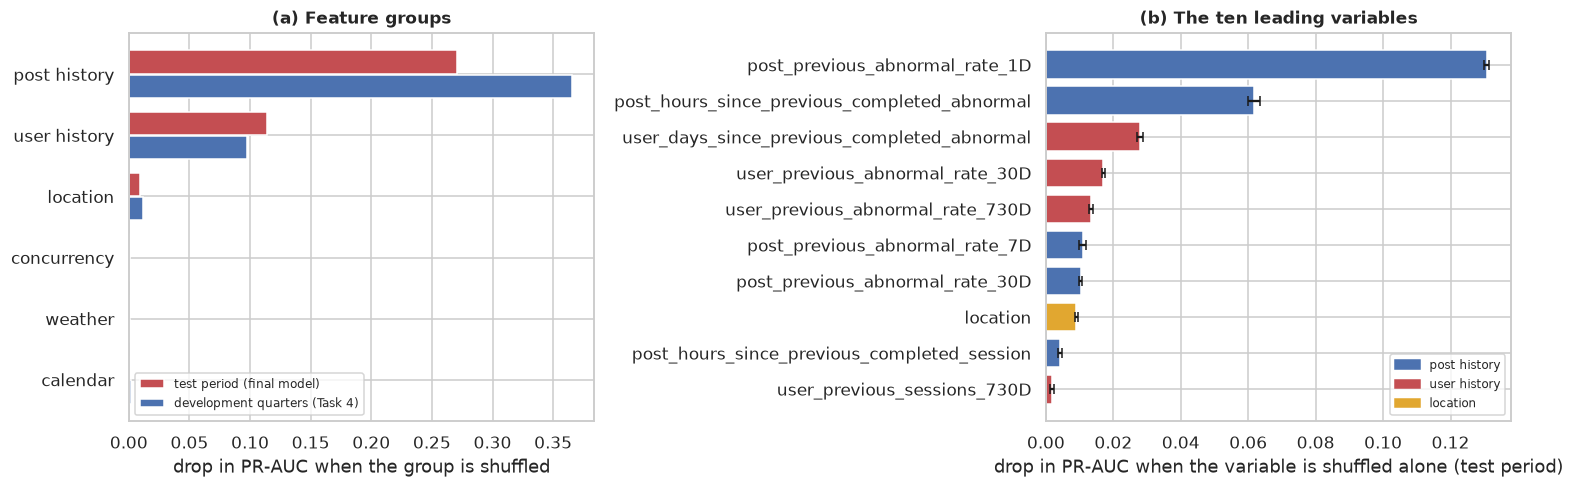

In [29]:
GROUPS = FEATURE_GROUPS["groups"]
INTERP_GROUPS = {"calendar": GROUPS["calendar"], "location": [c for c in GROUPS["location"] if c in FEATURES], "weather": GROUPS["weather"],
                 "post history": GROUPS["post_history"], "user history": GROUPS["user_history"], "concurrency": GROUPS["concurrency"]}
assert sorted(c for cols in INTERP_GROUPS.values() for c in cols) == sorted(FEATURES)


def permutation_drop(model, X, y, columns, repeats, rng):
    """PR-AUC drops when the rows of `columns` are shuffled jointly (one permutation per repeat, applied to every column of the group)."""
    base = average_precision_score(y, model.predict_proba(X)[:, 1])
    drops = []
    for _ in range(repeats):
        Xp = X.copy()
        perm = rng.permutation(len(X))
        for c in columns:
            Xp[c] = X[c].to_numpy()[perm]
        drops.append(base - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
    return drops


rng_perm = np.random.default_rng(SEED)
X_test = test[FEATURES]
t0 = time.time()
group_drops = {g: permutation_drop(final_model, X_test, y_test, cols, 5, rng_perm) for g, cols in INTERP_GROUPS.items()}
var_drops = {c: permutation_drop(final_model, X_test, y_test, [c], 3, rng_perm) for c in FEATURES}
print(f"permutation importance on the test period computed in {time.time() - t0:.0f} s (base PR-AUC {pr_final:.4f})")

dev_groups = {r["name"]: r for r in TASK4["importance"]["groups"]}
dev_vars = {r["name"]: r for r in TASK4["importance"]["variables"]}
group_importance = pd.DataFrame({"features": {g: len(c) for g, c in INTERP_GROUPS.items()},
                                 "test: PR-AUC drop": {g: np.mean(d) for g, d in group_drops.items()},
                                 "test: std": {g: np.std(d, ddof=1) for g, d in group_drops.items()},
                                 "development (Task 4): PR-AUC drop": {g: dev_groups[g]["PR-AUC drop"] for g in INTERP_GROUPS}}).sort_values("test: PR-AUC drop", ascending=False)
group_importance["test as a share of development"] = group_importance["test: PR-AUC drop"] / group_importance["development (Task 4): PR-AUC drop"]
display(group_importance.style.format({"test: PR-AUC drop": "{:.4f}", "test: std": "{:.4f}", "development (Task 4): PR-AUC drop": "{:.4f}", "test as a share of development": "{:.0%}"}))
var_importance = pd.DataFrame({"group": {c: g for g, cols in INTERP_GROUPS.items() for c in cols}, "test: PR-AUC drop": {c: np.mean(d) for c, d in var_drops.items()},
                               "test: std": {c: np.std(d, ddof=1) for c, d in var_drops.items()},
                               "development (Task 4): PR-AUC drop": {c: dev_vars[c]["PR-AUC drop"] for c in FEATURES}}).sort_values("test: PR-AUC drop", ascending=False)
display(var_importance.head(10).style.format({"test: PR-AUC drop": "{:.4f}", "test: std": "{:.4f}", "development (Task 4): PR-AUC drop": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
g = group_importance.iloc[::-1]
axes[0].barh(np.arange(len(g)) + 0.2, g["test: PR-AUC drop"], height=0.38, color=C_ABN, label="test period (final model)")
axes[0].barh(np.arange(len(g)) - 0.2, g["development (Task 4): PR-AUC drop"], height=0.38, color=C_NORMAL, label="development quarters (Task 4)")
axes[0].set_yticks(np.arange(len(g))); axes[0].set_yticklabels(g.index)
axes[0].set_xlabel("drop in PR-AUC when the group is shuffled"); axes[0].set_title("(a) Feature groups"); axes[0].legend(fontsize=8)
v = var_importance.head(10).iloc[::-1]
palette = dict(zip(INTERP_GROUPS, [C_GREY, C_ORANGE, C_GREEN, C_NORMAL, C_ABN, C_PURPLE]))
axes[1].barh(v.index, v["test: PR-AUC drop"], xerr=v["test: std"], color=[palette[x] for x in v["group"]], capsize=3)
axes[1].set_xlabel("drop in PR-AUC when the variable is shuffled alone (test period)"); axes[1].set_title("(b) The ten leading variables")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[x]) for x in dict.fromkeys(v["group"][::-1])], labels=list(dict.fromkeys(v["group"][::-1])), fontsize=8, loc="lower right")
fig.tight_layout()
savefig(fig, "09_1_permutation_importance")

The model relies on the same two groups in the same order as in development. On the test period, shuffling the post history lowers the PR-AUC by 0.271 and shuffling the user history by 0.114; location costs 0.009 and concurrency, weather and calendar less than 0.001 each, so the model barely uses them. The Task 4 values on the four validation quarters are 0.366 for the post history and 0.097 for the user history.
Two changes stand out. The post history counts for less than before (74% of its development value), and the user history for more (117%). Because the test PR-AUC is lower (0.532 against 0.626), all the drops are expected to be smaller, so the rise of the user history is stronger than the figures suggest.

Among single variables, the abnormal rate of the post in the last day is still the leading one (0.131, against 0.196 in development), but the time since the last abnormal session of the post grows from 0.038 to 0.062, and the user variables gain weight: the days since the last abnormal session of the user (0.028), the abnormal rate of the user in 30 days (0.017, against 0.007) and in 730 days (0.013). The 7-day rate that B1 uses falls to 0.011 (from 0.026), well behind the two variables
that give the most recent information on the post. The standard deviations over the shuffles are at most 0.0017, so they are not what limits the comparison: the limit is that the development values come from four different fitted models.

### 9.2 The shape of the effects: partial dependence

Partial dependence is not in the course slides. We use it because it is the model-based version of the decile curves of Task 1: those show the abnormal share as one history variable rises, and partial dependence shows the average score of the model as one variable moves while the others stay as observed. It is computed on a random sample of 20,000 test sessions with the final model. It needs complete values to build its grid, so we take the two most important variables
without missing values of each of the two information groups that the model uses, post history and user history. The dashed line is the abnormal share of the test period. The hours
since the last abnormal session of the post are drawn for the first 48 hours only, because the effect is concentrated there.

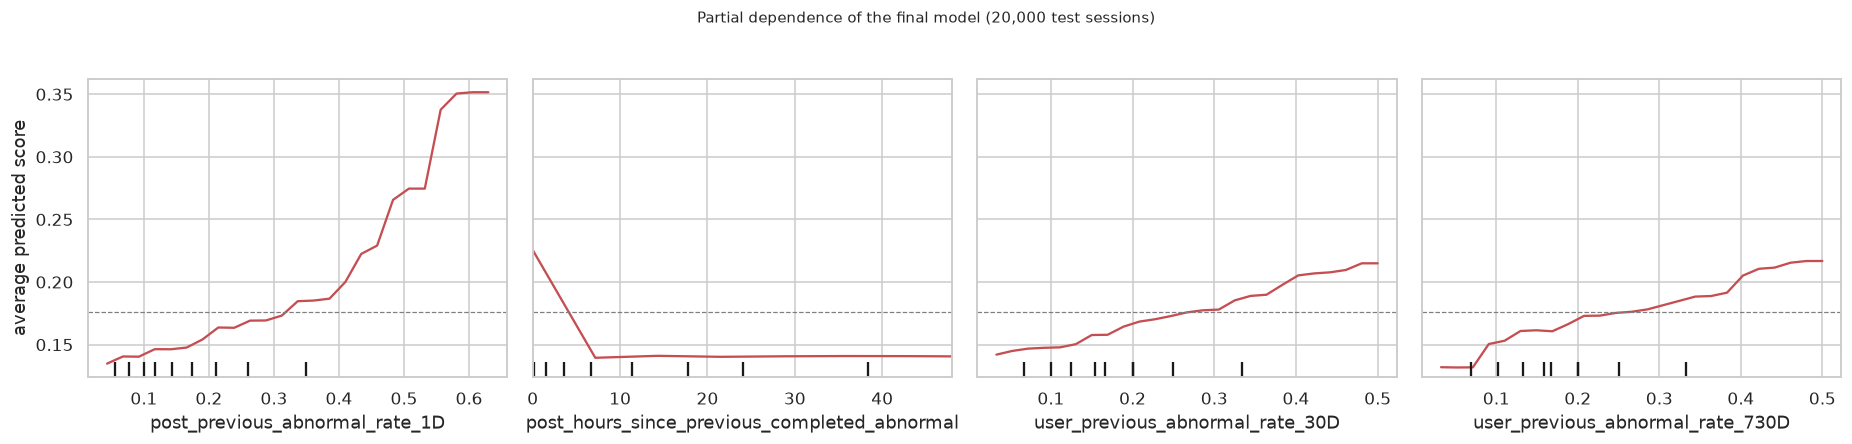

Variables shown: ['post_previous_abnormal_rate_1D', 'post_hours_since_previous_completed_abnormal', 'user_previous_abnormal_rate_30D', 'user_previous_abnormal_rate_730D']


In [30]:
pd_sample = test.sample(20_000, random_state=SEED)[FEATURES]
excluded = set(FEATURE_GROUPS["categorical"]) | set(FEATURE_GROUPS["binary"]) | {"hour", "dow"}
complete = [c for c in var_importance.index if pd_sample[c].notna().all() and c not in excluded]
pdp_vars = [c for c in complete if c in INTERP_GROUPS["post history"]][:2] + [c for c in complete if c in INTERP_GROUPS["user history"]][:2]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
PartialDependenceDisplay.from_estimator(final_model, pd_sample, features=pdp_vars, kind="average", grid_resolution=25, percentiles=(0.02, 0.98), ax=axes, line_kw={"color": C_ABN})
for ax, name in zip(axes, pdp_vars):
    ax.axhline(y_test.mean(), color=C_GREY, ls="--", lw=0.8)
    ax.set_ylabel("")
    if name == "post_hours_since_previous_completed_abnormal":
        ax.set_xlim(0, 48)
axes[0].set_ylabel("average predicted score")
fig.suptitle("Partial dependence of the final model (20,000 test sessions)", fontsize=10, y=1.03)
fig.tight_layout()
savefig(fig, "09_2_partial_dependence")
print("Variables shown:", pdp_vars)

The average predicted score stays between 0.13 and 0.17 while the 1-day abnormal rate of the post is below 0.3, then rises faster and reaches about 0.35 at a rate of 0.6, so the model reacts to a post that is failing and not to small differences in a healthy one. For the time since the last abnormal session, the score is about 0.23 right after a failure and falls to about 0.14 in the first hours (the grid is too coarse to resolve the first 7 hours) and stays flat afterwards: the signal is
"a failure at this post a few hours ago", not a slow decay. The two user variables raise the score gradually, from about 0.14 to about 0.22 as the abnormal rate of the user goes from near 0 to 0.5, an effect much smaller than that of the post. All the effects have the expected direction, with no sign of a reversed or irregular relation, and the score is above the abnormal share of the test (dashed line, 0.176) only from a 1-day post rate of about 0.3, or from a user rate of about 0.25 to 0.3.

### 9.3 What this interpretation cannot tell us

These methods describe how the fitted model uses its inputs, not what causes failures. Permutation importance gives an importance to correlated variables jointly: when a single window is shuffled, the other windows still carry part of its information, so the single-variable values understate each of them, and the group values avoid this only for the ranking of groups. A shuffled group can also create combinations
of values that never occur (a low 1-day rate with a failure a minute ago), on which the model is not meant to work. Partial dependence has the same weakness, since it assumes that a variable can vary on its own while the others stay as observed, and the 1-day rate and the time since the last failure of the post are strongly linked. It also averages over sessions, so it hides differences between them; individual conditional curves would show them.
Both methods use the test labels here, so they are descriptive, and they explain the model as a whole, not why a given session was flagged; for that we would need a local method such as SHAP, which the course does not cover and we did not implement. Finally, the two leading groups are made of earlier outcomes (failures at the post and of the user), so "the history matters" says that the model reads recent failures, not what makes a post fail.

---
## 10. Practical consequences of the threshold and usefulness of the model

### 10.1 What the frozen cut-off means for an operator

The cut-off of 0.490 is a score, not a number of alerts, so the workload follows the number of sessions and the level of failures. The table translates the test result into
daily work. A session is an alert if its score is at least the cut-off. Posts with an alert are counted once per day.

In [31]:
test["date"] = test["start_time"].dt.normalize()
daily = test.groupby("date").agg(sessions=("flag", "size"), alerts=("flag", "sum"), abnormal=(TARGET, "sum"))
daily["correct alerts"] = test[test["flag"] & (test[TARGET] == 1)].groupby("date").size().reindex(daily.index).fillna(0)
daily["false alerts"] = daily["alerts"] - daily["correct alerts"]
daily["missed"] = daily["abnormal"] - daily["correct alerts"]
daily["posts with an alert"] = test[test["flag"]].groupby("date")["post_id"].nunique().reindex(daily.index).fillna(0)
daily["alert rate"] = daily["alerts"] / daily["sessions"]
per_day = pd.DataFrame({"mean per day": daily.mean(), "minimum": daily.min(), "maximum": daily.max()}).loc[
    ["sessions", "alerts", "correct alerts", "false alerts", "missed", "posts with an alert", "alert rate"]]
display(per_day.style.format("{:.1f}").format({"mean per day": "{:.3f}", "minimum": "{:.3f}", "maximum": "{:.3f}"}, subset=pd.IndexSlice[["alert rate"], :]))
print(f"{len(daily)} days in the test period | the 10% target would give {0.10 * daily['sessions'].mean():.1f} alerts per day; the frozen cut-off gives {daily['alerts'].mean():.1f}")

,mean per day,minimum,maximum
sessions,870.4,668.0,1128.0
alerts,64.6,18.0,210.0
correct alerts,43.8,10.0,156.0
false alerts,20.9,7.0,54.0
missed,109.4,61.0,164.0
posts with an alert,19.8,10.0,30.0
alert rate,0.073,0.022,0.192


92 days in the test period | the 10% target would give 87.0 alerts per day; the frozen cut-off gives 64.6


On an average day the test period has 870 sessions and the frozen cut-off raises 64.6 alerts, of which 43.8 are correct and 20.9 are false, and 109.4 abnormal sessions go without an alert. The alerts come from 19.8 posts a day on average (10 to 30), about three alerts per post, so the number of inspections is lower than the number of alerts. The daily alert rate is 7.3% on average and goes
from 2.2% to 19.2%, which is 18 to 210 alerts a day. The 10% target would give 87.0 alerts a day, 22.4 more than the cut-off gives. The workload follows the failures: on a bad day the operator receives three times the average number of alerts, and a team sized for the average would be overwhelmed. If the team has a daily capacity, the alternative is to inspect only
the highest scores of each day. Even in a quiet day, the model finds only a part of the failures: the 109 sessions missed a day are about 1.7 times the 65 alerts, so the model is a tool to prioritise the posts that are failing, not a complete detector.

### 10.2 What a different capacity would give

The 10% budget was an assumption. The table applies the three budgets of the protocol to the test scores (the sessions with the highest scores, ties broken at random), next to the
frozen cut-off and next to the cut-off that would flag exactly 10% of the test sessions. These cut-offs are computed from the test scores after the fact. They only show what another capacity would
have given on this quarter, they did not exist when the cut-off was chosen, and the frozen cut-off of 0.490 is the one in force. The figure shows how precision, recall and the alert rate change with the cut-off on the test scores.

,cut-off,precision,recall,F1,alert rate,"correct per 1,000","false per 1,000","missed per 1,000"
frozen cut-off 0.490,0.490,0.677,0.286,0.402,7.4%,50.3,24.0,125.6
top 5% of the scores,0.577,0.766,0.218,0.339,5.0%,38.3,11.7,137.6
top 10% of the scores,0.413,0.614,0.349,0.445,10.0%,61.4,38.6,114.5
top 20% of the scores,0.245,0.466,0.529,0.495,20.0%,93.1,106.9,82.8


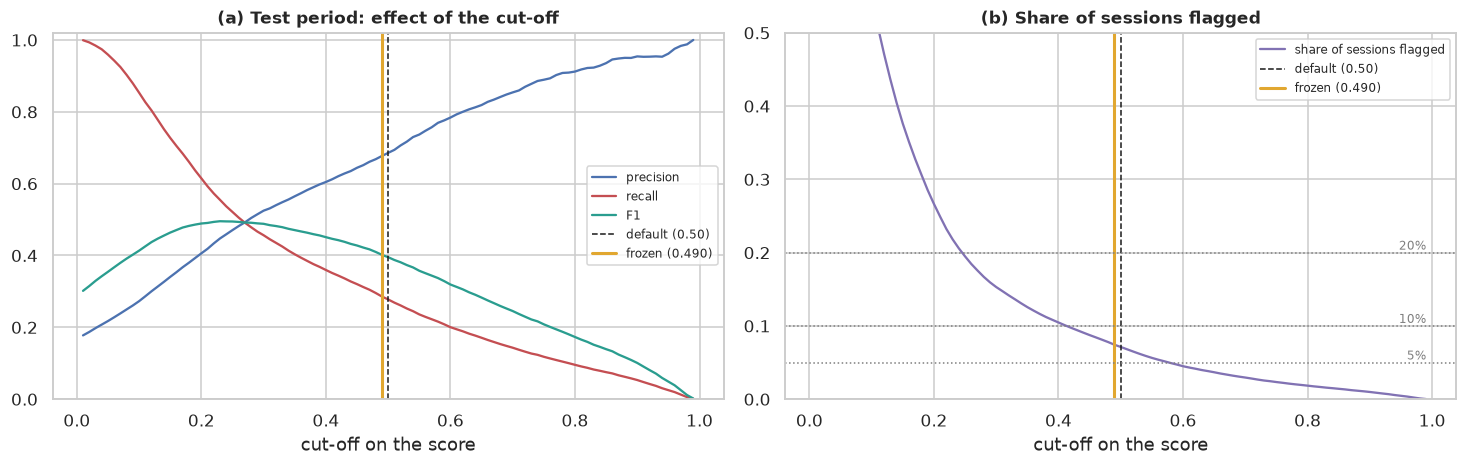

In [32]:
budget_rows = {f"frozen cut-off {CUT_OFF:.3f}": flag_final}
for q in ALERT_BUDGETS:
    budget_rows[f"top {q:.0%} of the scores"] = top_k_flags(p_test, int(round(q * len(p_test))))
budget_table = pd.DataFrame({name: confusion_metrics(y_test, flagged) for name, flagged in budget_rows.items()}).T
budget_table["cut-off"] = [CUT_OFF] + [float(np.sort(p_test)[::-1][int(round(q * len(p_test))) - 1]) for q in ALERT_BUDGETS]
display(budget_table[["cut-off", "precision", "recall", "F1", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]].style.format(
    {"cut-off": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "alert rate": "{:.1%}", "correct per 1,000": "{:.1f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}"}))

grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
curve = pd.DataFrame([{"cut-off": t, **confusion_metrics(y_test, p_test >= t)} for t in grid])
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].plot(grid, curve["precision"], color=C_NORMAL, label="precision"); axes[0].plot(grid, curve["recall"], color=C_ABN, label="recall"); axes[0].plot(grid, curve["F1"], color=C_GREEN, label="F1")
axes[1].plot(grid, curve["alert rate"], color=C_PURPLE, label="share of sessions flagged")
for ax in axes:
    ax.axvline(0.5, color="k", ls="--", lw=1, label="default (0.50)")
    ax.axvline(CUT_OFF, color=C_ORANGE, lw=2, label=f"frozen ({CUT_OFF:.3f})")
    ax.set_xlabel("cut-off on the score")
axes[0].set_ylim(0, 1.02); axes[0].set_title("(a) Test period: effect of the cut-off"); axes[0].legend(fontsize=8, loc="center right")
for q in ALERT_BUDGETS:
    axes[1].axhline(q, color=C_GREY, ls=":", lw=1); axes[1].text(0.99, q, f"{q:.0%}", ha="right", va="bottom", fontsize=8, color=C_GREY)
axes[1].set_ylim(0, 0.5); axes[1].set_title("(b) Share of sessions flagged"); axes[1].legend(fontsize=8, loc="upper right")
fig.tight_layout()
savefig(fig, "10_1_threshold_on_test")

With the sessions of highest score, the three budgets of the protocol give, per 1,000 sessions, 38.3 correct and 11.7 false alerts at 5% (precision 0.766, recall 0.218), 61.4 and 38.6 at 10% (0.614, 0.349) and 93.1 and 106.9 at 20% (0.466, 0.529). The cut-offs that would give these budgets on the test scores are 0.577, 0.413 and 0.245. The frozen cut-off of 0.490 sits between the first two. On these test scores, flagging
exactly 10% of the sessions takes a cut-off of 0.413, a value that can only be known after the test. Going from 5% to 10% adds 23.1 correct alerts for 26.9 false ones (marginal precision 0.46), and from 10% to 20% adds 31.7 correct for 68.3 false (0.32), more than two false alerts for each extra failure found. In development the step from 5% to 10% was still better than even (Task 4: 29.3 correct against 20.7 false), so the quarter makes extra alerts less worthwhile.
The figure shows that the F1-score on the test peaks near a cut-off of 0.2 to 0.3, well below the frozen cut-off (F1 of 0.402 at the frozen cut-off, about 0.50 at the peak). The protocol does not use F1 to choose, so none of these after-the-fact cut-offs replaces the frozen 0.490.

### 10.3 Is the model worth using? Costs of the two errors

Task 2 left the cost ratio `c` (cost of a missed failure divided by cost of a false alert) open. Instead of fixing it, we ask for which values of `c` an operator is better off
with the model than without it. The cost per 1,000 sessions is measured in false alerts (one false alert costs 1): `cost = false alerts + c × missed failures`. The model is compared
with three alternatives: no alerts at all (every failure is missed), an alert on every session (every normal session is a false alert) and B1 with the same number of alerts. The
evaluation lab used `c = 10`; the other values show how the result depends on it. These costs are an assumption of this notebook, not data.

In [33]:
n = len(y_test)
final_m = confusion_metrics(y_test, flag_final)
b1_m = confusion_metrics(y_test, flag_b1_matched)
abnormal_per_1000, normal_per_1000 = 1000 * y_test.mean(), 1000 * (1 - y_test.mean())
options = {"final model": (final_m["false per 1,000"], final_m["missed per 1,000"]), "B1, same number of alerts": (b1_m["false per 1,000"], b1_m["missed per 1,000"]),
           "no alerts": (0.0, abnormal_per_1000), "alert on every session": (normal_per_1000, 0.0)}
cost_table = pd.DataFrame({f"c = {c}": {name: fp + c * fn for name, (fp, fn) in options.items()} for c in (1, 2, 3, 5, 10)})
cost_table["cheapest option"] = ""
cheapest = cost_table.drop(columns="cheapest option").idxmin()
display(cost_table.drop(columns="cheapest option").style.format("{:.1f}").highlight_min(axis=0, color="#d8f0d8"))
lower = final_m["false per 1,000"] / final_m["correct per 1,000"]
upper = (normal_per_1000 - final_m["false per 1,000"]) / final_m["missed per 1,000"]
print(f"Per 1,000 sessions: {abnormal_per_1000:.1f} abnormal and {normal_per_1000:.1f} normal. Cheapest option by c: {cheapest.to_dict()}")
print(f"The final model costs less than no alerts when c > {lower:.2f} and less than an alert on every session when c < {upper:.2f}.")
print(f"Against B1 with the same number of alerts: {final_m['correct per 1,000'] - b1_m['correct per 1,000']:+.1f} correct, "
      f"{final_m['false per 1,000'] - b1_m['false per 1,000']:+.1f} false and {final_m['missed per 1,000'] - b1_m['missed per 1,000']:+.1f} missed alerts per 1,000 sessions.")

# If an operator did know c, the cut-off of Task 2 (Section 5) would be t* = 1 / (1 + c), valid when the scores are probabilities (Task 4 found them close to calibrated).
# The rule uses only c, not the test labels. The table shows what each value of c would give next to the frozen cut-off; it is a what-if and changes nothing.
rows = {}
for c in (1, 2, 3, 5, 10):
    t = 1 / (1 + c)
    m = confusion_metrics(y_test, p_test >= t)
    own, frozen_cost = m["false per 1,000"] + c * m["missed per 1,000"], final_m["false per 1,000"] + c * final_m["missed per 1,000"]
    rows[f"c = {c}"] = {"cut-off t*": t, "alert rate": m["alert rate"], "precision": m["precision"], "recall": m["recall"], "false per 1,000": m["false per 1,000"],
                        "missed per 1,000": m["missed per 1,000"], "cost with t*": own, "cost with the frozen cut-off": frozen_cost, "saving": frozen_cost - own}
cost_cutoff_table = pd.DataFrame(rows).T
display(cost_cutoff_table.style.format({"cut-off t*": "{:.3f}", "alert rate": "{:.1%}", "precision": "{:.3f}", "recall": "{:.3f}", "false per 1,000": "{:.1f}", "missed per 1,000": "{:.1f}",
                                        "cost with t*": "{:.1f}", "cost with the frozen cut-off": "{:.1f}", "saving": "{:.1f}"}))

,c = 1,c = 2,c = 3,c = 5,c = 10
final model,149.6,275.3,400.9,652.2,1280.5
"B1, same number of alerts",174.5,312.6,450.7,726.9,1417.4
no alerts,175.9,351.8,527.8,879.6,1759.2
alert on every session,824.1,824.1,824.1,824.1,824.1


Per 1,000 sessions: 175.9 abnormal and 824.1 normal. Cheapest option by c: {'c = 1': 'final model', 'c = 2': 'final model', 'c = 3': 'final model', 'c = 5': 'final model', 'c = 10': 'alert on every session'}
The final model costs less than no alerts when c > 0.48 and less than an alert on every session when c < 6.37.
Against B1 with the same number of alerts: +12.4 correct, -12.4 false and -12.4 missed alerts per 1,000 sessions.


,cut-off t*,alert rate,precision,recall,"false per 1,000","missed per 1,000",cost with t*,cost with the frozen cut-off,saving
c = 1,0.500,7.1%,0.686,0.278,22.4,127.1,149.5,149.6,0.2
c = 2,0.333,13.4%,0.551,0.421,60.3,101.8,264.0,275.3,11.3
c = 3,0.250,19.5%,0.471,0.521,103.1,84.2,355.9,400.9,45.1
c = 5,0.167,33.5%,0.363,0.691,213.7,54.3,485.2,652.2,167.1
c = 10,0.091,58.9%,0.262,0.877,434.9,21.7,651.8,1280.5,628.6


For a cost of one false alert and c for a missed failure, the final model is the cheapest of the four options for c from 1 to 5. At c = 10, the value of the evaluation lab, an alert on every session is cheaper (824.1 against 1,280.5 per 1,000 sessions). The model costs less than no alerts when c is above 0.48 (false alerts divided by correct alerts) and less than alerting every session when c is below 6.37. Against B1 with the same number of alerts, the model is cheaper for any c, because it
has 12.4 more correct alerts, 12.4 fewer false alerts and 12.4 fewer missed sessions per 1,000.

The cost-based cut-off of Task 2, t* = 1/(1 + c), tells us which cost ratio the frozen cut-off assumes. For c = 1 it is 0.500, almost the frozen 0.490 (the costs differ by 0.2 per 1,000 sessions), which is the cost ratio of about 1.04 that Task 4 found. On the test scores, a higher c would have meant a lower cut-off and much more work: at c = 2 (t* = 0.333) the alert rate would be 13.4% and the cost 264.0 instead of 275.3; at c = 5 (t* = 0.167) it would be 33.5%, with a
precision of 0.363 and a recall of 0.691, and the cost 485.2 instead of 652.2; at c = 10 (t* = 0.091) it would be 58.9% with a precision of 0.262 and a recall of 0.877, and the cost 651.8, below the 824.1 of alerting every session. These figures come from the test period, so they describe what the frozen cut-off assumes and cannot be used to set it; the frozen 0.490 stays. It fits a missed failure that costs about as much as a false alert, while Task 2 argued that a miss costs more, so the cost ratio is the main assumption behind the operating point.
That ratio and the capacity are not in the data. They have to come from the operator, and a new cut-off would be chosen from them on development data at a future refit.

In [34]:
log_decision("10", "Threshold consequences and usefulness", "The frozen cut-off is kept; the capacity and cost ratio remain assumptions and are reported as ranges.",
             f"On average {daily['alerts'].mean():.0f} alerts per day ({daily['false alerts'].mean():.0f} false) for {daily['sessions'].mean():.0f} sessions; the model costs less than no alerts "
             f"for c > {lower:.2f} and less than alerting every session for c < {upper:.2f}.")

---
## 11. Conclusions, limitations and recommendations

### 11.1 Main findings

The final model is gradient boosting with its Task 3 configuration (200 trees of depth 6). Its mean development PR-AUC is 0.626, within the tolerance of the random forest (0.622), and we chose it for its better worst fold, its lower variation between folds and a cost four times smaller. Tuning did not improve it, and the baseline is B1, the 7-day abnormal rate of the post.

On the test period the model reaches a PR-AUC of 0.532, against 0.381 for B1 and 0.178 for no skill, a gain of 0.152 over B1 (interval +0.145 to +0.158) that is larger than in any development fold. At the frozen cut-off of 0.490 it flags 7.4% of the sessions with a precision of 0.677, a recall of 0.286, an F1 of 0.402, a balanced accuracy of 0.628 and an MCC of 0.373: 50.3 correct alerts, 24.0 false alerts and 125.6 missed abnormal sessions per 1,000 sessions.

The fall from development is mostly arithmetic: 87% of the drop in PR-AUC from fold 4 comes from the lower abnormal share (21.1% to 17.6%). The ranking did weaken (ROC-AUC 0.838 to 0.794, lift 3.12 to 3.03, a decline that was already visible in development), and B1 weakened more. We see no drift inside the quarter.

The model beats B1 in every district and station. It works best at the posts that are failing now, where 9 posts take 46.4% of the alerts, and worst in low-failure stations, for new users (recall 0.146) and for failures that start more than 6 hours after the last failure of the post, which hold 52.9% of all missed failures. The false positives look like the true positives (a failure at the post minutes before), and the missed failures look like normal sessions. The causes least detected are the DC output fault, the BMS failure, the faulty connection and the control-loop failure (recall 0.19 to 0.22). The model relies on the post history, then on the user history, and the user history gains weight on the test.

For its operator, the model costs less than no alerts for c above 0.48 and less than alerting every session for c below 6.37. It gives about 65 alerts a day (21 false), concentrated in about 20 posts, which helps to prioritise the posts that are failing, but it finds only 29% of the failures, so it cannot work as a complete detector.

### 11.2 Limitations

The test result is one quarter of 80,081 sessions, so it measures that quarter and not a long-run average, and it was scored first in Task 4, which means that no analysis in this notebook could have changed a choice, but also that we have no second test. The capacity of the operator and the cost ratio are unknown: the 10% budget is an assumption, the frozen cut-off corresponds to a cost ratio of about 1, and the costs of Section 10.3 are an assumption of the notebook.
Subgroup, weekly and per-post results come from the same quarter, some of them from few abnormal sessions, and only the overall comparison has a confidence interval, so small differences between groups should not be read as findings. The bootstrap and the McNemar test treat sessions as independent, which they are not. The model depends on histories that are supplied with the data and assumed available at the start of the session, and on weather taken as a forecast (Task 2).
The error analysis uses the end cause only after the fact, and three causes have fewer than 20 test sessions. The calibration of the scores was checked on the development quarters (Task 4) and not on the test. The interpretation has the limits of Section 9.3, and the user history is a behaviour profile of identified drivers, which raises the privacy question that Task 2 noted.

### 11.3 Recommendations for future improvement

Several improvements follow from these results. The first is to keep the model current: refit it every quarter with the rolling origin used here and follow the lift, the ROC-AUC and the alert rate week by week. The development ROC-AUC lay between 0.825 and 0.844 and the test is at 0.794, so a value below the development range is a reasonable trigger for a review, and the reliability of the scores should be checked on the most recent quarter before a score is read as a probability. The operator should also give us the real cost of a missed failure and the daily inspection capacity before the next refit, so that the cut-off is set from them on development data instead of from our assumed 10%. With a fixed team, inspecting the highest scores of each day would keep the workload steady, and grouping the alerts by post and day (about three alerts per alerted post) would match how maintenance is organised.

The other improvements concern the failures the model misses. It sees almost nothing of the 52.9% of missed failures that follow more than 6 hours without a failure at the post. Variables known at the start of a session that are not in this dataset (age, maintenance record and firmware of the post, charger type, vehicle model), or telemetry from the previous sessions, could help there. New users, with a recall of 0.146, could get a fallback based on the post only, unless the platform can identify the account before the start. Finally, the target merges 13 causes, and the model finds some (DC switching device, recall 0.50) much better than others (BMS, DC output, control loop, about 0.2), so a model per group of causes, or a cost per cause, would let the operator act on the severe faults first.

---
## 12. Saved files and decision log

The notebook writes its results (`prepared/task5_results.json`), the decision log (`prepared/task5_decision_log.csv`) and its figures (`prepared/figures_task5/`). It reads the Task 4 files
and changes none of them. The last check confirms that the frozen file is the one that Section 1 hashed.

In [35]:
def records(frame):
    return json.loads(frame.reset_index().to_json(orient="records", date_format="iso"))


RESULTS = {
    "note": "Task 4 scored the test period once on 2026-10-27; this notebook reproduces that score from the frozen file and adds descriptive analyses. No choice was changed.",
    "frozen_file": {"path": str(FROZEN_FILE), "sha256": FROZEN_HASH, "frozen_at": FROZEN["frozen_at"]},
    "final_model": {"model": FROZEN["model"], "configuration": FROZEN["configuration"], "cut_off": CUT_OFF, "baseline": "B1 post failure rate (7 days)", "baseline_cut_off": B1_CUT},
    "selection": {"candidates": records(candidates), "within_tolerance": list(step1.index), "selected": SELECTED_NAME},
    "test": {"sessions": int(len(test)), "abnormal_share": float(y_test.mean()), "PR-AUC": {"final": pr_final, "B1": pr_b1, "B0": pr_b0},
             "PR-AUC_gain_over_B1": {"value": pr_final - pr_b1, "bootstrap_95_interval": list(gain_ci)}, "mcnemar": {"only_final_right": only_final, "only_b1_right": only_b1, "p": mcnemar_p},
             "comparison": records(comparison[["PR-AUC"] + COLUMNS[1:] + ["TP", "FP", "FN", "TN"]]), "development_vs_test": records(dev_vs_test)},
    "time": {"periods": records(time_table), "weekly": records(weekly), "fall_from_fold_4_to_test": FALL_SPLIT},
    "groups": {"districts": records(district_table), "stations": records(station_table), "users": records(user_table), "posts_concentration": concentration},
    "error_analysis": {"outcomes": {k_: int(v_) for k_, v_ in outcome_counts.items()}, "end_causes": records(cause_table), "bands": records(band_table)},
    "interpretation": {"groups": records(group_importance), "top_variables": records(var_importance.head(10)), "partial_dependence_variables": pdp_vars},
    "operations": {"per_day": records(per_day), "budgets_on_test": records(budget_table[["cut-off", "precision", "recall", "F1", "alert rate", "correct per 1,000", "false per 1,000", "missed per 1,000"]]),
                   "costs": records(cost_table.drop(columns="cheapest option")), "cost_based_cut_offs": records(cost_cutoff_table), "break_even_c": {"lower": lower, "upper": upper}},
}
(OUT_DIR / "task5_results.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=float))
decision_log = pd.DataFrame(DECISIONS)
decision_log.to_csv(OUT_DIR / "task5_decision_log.csv", index=False)
assert FROZEN_HASH == hashlib.sha256(FROZEN_FILE.read_bytes()).hexdigest()
print("Saved: task5_results.json, task5_decision_log.csv | figures in", FIG_DIR, "| the frozen file is unchanged")
display(decision_log.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

Saved: task5_results.json, task5_decision_log.csv | figures in prepared/figures_task5 | the frozen file is unchanged


section,topic,decision,evidence
2,Final model,"Gradient boosting, HGB depth=6, lr=0.1, 200 it, leaf=100, 27 features; baseline B1 (7-day failure rate of the post), B0 as the chance reference.","Mean PR-AUC 0.626, within the tolerance of 0.005 of the random forest (0.622), with the better worst fold and standard deviation, the lower cost per fold and no tuned configuration that passed the rule of Task 4. Selection used development results only."
2,Threshold,"Cut-off 0.4899 from the 10% alert rate on the pooled out-of-fold predictions (Task 4), no calibrator.","Development operating point: precision 0.740, recall 0.403; calibration gap at most 0.015."
3,Refit and baseline cut-off,"Final model refitted on 346,931 development sessions; B1 cut-off 0.3931 from the same 10% criterion on development data.",48 sessions purged (ended on or after the test start); the four-fold refit reproduces the frozen mean PR-AUC (0.6258) and the frozen cut-off (0.4899).
4,Test scoring,The frozen model scores the test period; nothing is changed after this point and every later analysis is descriptive.,"Test PR-AUC 0.5324, equal to the Task 4 value 0.5324; alert rate 7.43% at the frozen cut-off; frozen file unchanged (SHA-256 d1ee31cb76ac...)."
5,Comparison with the baseline,Reported as observed at the frozen operating points; no choice changes.,"Test PR-AUC 0.5324 against 0.3809 for B1 (gain +0.1516, 95% interval [+0.1449, +0.1580]); at the frozen cut-off: precision 0.677, recall 0.286, F1 0.402, balanced accuracy 0.628, MCC 0.373, alert rate 7.43%."
6-7,Time and group analysis,Descriptive only: the frozen cut-off is applied everywhere and no group-specific threshold is introduced.,"Test months PR-AUC 0.553, 0.483, 0.551; districts 3, stations 12, posts 88."
8,Error analysis,"Descriptive: patterns by failure type, post history, user, time of day, weather, district and post. No change to the model or the cut-off.","At the frozen cut-off: 4,026 true positives, 1,921 false positives, 10,062 false negatives; overall recall 0.286 over 12 end causes."
10,Threshold consequences and usefulness,The frozen cut-off is kept; the capacity and cost ratio remain assumptions and are reported as ranges.,On average 65 alerts per day (21 false) for 870 sessions; the model costs less than no alerts for c > 0.48 and less than alerting every session for c < 6.37.
